# Triagem de raio-X de tórax com Autoencoders Variacionais (VAE)

**Prova de conceito:** um VAE treinado **somente com exames normais** consegue apontar quais raios-X fogem do padrão, indicar *onde* está a alteração e reordenar uma fila de exames?

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rmotti/vaes_poc/blob/main/notebooks/poc_vae_raiox.ipynb)

**Como rodar no Colab:** menu *Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)* e depois *Executar tudo*. Com GPU, o notebook inteiro leva cerca de 5 a 10 minutos (são 15 treinos curtos); em CPU funciona, mas é bem mais lento — nesse caso, desligue `rodar_ablacao` na configuração.

| Seção | Conteúdo |
|---|---|
| 0 | O problema e as perguntas da PoC |
| 1 | Fundamentação: autoencoders, VAEs e por que servem para detectar anomalias |
| 2 | Configuração do ambiente |
| 3 | Dados: PneumoniaMNIST |
| 4 | Arquitetura |
| 5 | Treinamento |
| 6 | O que o VAE aprendeu (reconstrução, geração, espaço latente) |
| 7 | Do erro de reconstrução ao score de anomalia (e por que a versão ingênua falha) |
| 8 | Avaliação experimental (métricas, baselines, limiar, simulação da fila, hiperparâmetros) |
| 9 | Análise de erros e atalhos |
| 10 | Conclusões e limitações |
| 11 | Salvando o modelo |

## 0. O problema

Em serviços de radiologia com alta demanda, exames de tórax podem esperar horas na fila até receberem laudo. Se a fila fosse **ordenada por prioridade** — exames com maior chance de alteração primeiro —, casos graves seriam vistos antes.

Esta PoC investiga se um **VAE treinado apenas com raios-X normais** consegue:

1. dar a cada exame um **score de anomalia** (o quanto ele foge do padrão normal);
2. indicar **onde** está a alteração, com um **mapa de calor**;
3. **reordenar a fila** de exames, colocando os alterados no topo.

**Por que não usar simplesmente um classificador?**

- Um classificador precisa de exemplos rotulados de *cada* doença que deve reconhecer. Um detector de anomalias aprende só o que é "normal" e, em princípio, sinaliza qualquer desvio — inclusive doenças que nunca viu.
- Exames normais são abundantes e baratos de rotular; doenças raras, não.
- O VAE entrega, além do score, uma reconstrução "normalizada" do exame — a diferença entre as duas mostra onde está o problema.

O preço é desempenho: sem ver nenhum exemplo da doença, é esperado que o VAE fique **abaixo** de um classificador supervisionado. A pergunta é *quanto*.

### Perguntas que a PoC precisa responder

| # | Pergunta | Onde é respondida |
|---|---|---|
| P1 | Um VAE que nunca viu pneumonia consegue separar pneumonia de normal? | Seções 7 e 8.1 |
| P2 | Ele é melhor que alternativas mais simples? Quão longe fica de um classificador supervisionado? | Seção 8.2 |
| P3 | O mapa de calor aponta regiões plausíveis? | Seções 7.4 e 9.1 |
| P4 | Na prática, quanto a fila de triagem melhoraria? | Seção 8.4 |
| P5 | Onde e por que ele erra? | Seção 9 |

> **Aviso:** prova de conceito acadêmica, feita com um conjunto de dados público e anonimizado. Não é um dispositivo médico e não deve ser usada para diagnóstico.

## 1. Fundamentação

### 1.1 Autoencoder

Um **autoencoder** é uma rede neural com duas partes:

- **Encoder** $f$: comprime a entrada $x$ (aqui, uma imagem de 64×64 = 4.096 pixels) em um vetor pequeno $z$ — o **código latente** (aqui, 8 números).
- **Decoder** $g$: tenta reconstruir a imagem a partir do código, $\hat{x} = g(z)$.

O treino minimiza o **erro de reconstrução** entre $x$ e $\hat{x}$. Como $z$ é muito menor que $x$, a rede é obrigada a guardar só a estrutura mais importante das imagens (um "gargalo").

**Limitação:** nada organiza o espaço onde os códigos $z$ ficam. Pontos entre dois códigos conhecidos, ou sorteados ao acaso, não correspondem a nada — o autoencoder comprime e reconstrói, mas **não sabe gerar** imagens novas.

### 1.2 Autoencoder Variacional (VAE)

O VAE (Kingma & Welling, 2014) faz duas mudanças:

**1. O encoder devolve uma distribuição, não um ponto.** Para cada imagem, ele produz uma média $\mu(x)$ e uma variância $\sigma^2(x)$, que definem uma gaussiana $q(z \mid x) = \mathcal{N}(\mu, \sigma^2)$. O código é **sorteado** dessa gaussiana.

Para que dê para treinar com backpropagation, o sorteio é escrito como

$$z = \mu + \sigma \odot \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I)$$

— o **truque da reparametrização**: a aleatoriedade fica isolada em $\varepsilon$ e os gradientes passam normalmente por $\mu$ e $\sigma$.

**2. A loss tem dois termos** (é o negativo da *ELBO*, o limite inferior da evidência):

$$\mathcal{L}(x) = \underbrace{-\,\mathbb{E}_{q(z\mid x)}\big[\log p(x \mid z)\big]}_{\text{reconstrução}} \;+\; \beta \cdot \underbrace{D_{KL}\big(q(z \mid x)\,\|\,\mathcal{N}(0, I)\big)}_{\text{regularização}}$$

- **Reconstrução:** a imagem gerada parece com a original? Aqui usamos a entropia cruzada binária (BCE) somada nos pixels, tratando cada pixel em [0, 1] como uma probabilidade.
- **Divergência KL:** o quanto a gaussiana de cada imagem se afasta de uma normal padrão. Para gaussianas ela tem fórmula fechada:
  $D_{KL} = -\tfrac{1}{2}\sum_j \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$.

**Intuição:** o termo de reconstrução quer dar a cada imagem um "cantinho" exclusivo e preciso no espaço latente; o termo KL puxa todos os códigos para perto da origem e impede que a rede "decore" imagens. O equilíbrio entre os dois produz um espaço latente **contínuo e organizado**: dá para **sortear** $z \sim \mathcal{N}(0, I)$ e gerar uma imagem nova e plausível, ou **interpolar** suavemente entre duas imagens.

O peso $\beta$ controla esse equilíbrio (β-VAE, Higgins et al., 2017): $\beta > 1$ organiza mais o espaço latente, ao custo de reconstruções mais borradas; $\beta < 1$ faz o contrário.

### 1.3 Por que um VAE detecta anomalias

Se o VAE é treinado **somente com exames normais**, o decoder só aprende a "desenhar" pulmões normais. Ao receber um exame com pneumonia, ele produz a versão "normalizada" daquele exame — a imagem que *seria esperada* se o paciente fosse saudável. A **diferença entre o exame e a reconstrução**:

- resumida em um número → **score de anomalia** (An & Cho, 2015);
- vista pixel a pixel → **mapa de calor** de onde está a alteração (Baur et al., 2021).

### 1.4 Limitações conhecidas da técnica

- **Reconstruções borradas:** o VAE tende a produzir a "média" das possibilidades, perdendo detalhes finos — mesmo em imagens normais.
- **Colapso do posterior:** se o termo KL domina, parte (ou todo) o espaço latente é ignorada pelo decoder. Uma mitigação comum é o *KL warm-up* (Bowman et al., 2016): começar com peso zero no KL e aumentá-lo aos poucos — usado aqui.
- **"Simples" parece "normal":** modelos generativos tendem a atribuir alta probabilidade (e baixo erro de reconstrução) a imagens *mais simples*, mesmo que sejam de outra distribuição (Nalisnick et al., 2019; Serrà et al., 2020). **Vamos ver isso acontecer na Seção 7.**
- **Dependência do "normal" representativo:** qualquer variação normal ausente no treino (outro equipamento, outra faixa etária) vira falso alarme.
- **Geração de qualidade inferior** a GANs e modelos de difusão (embora o VAE seja peça central do Stable Diffusion, como compressor de imagens).

## 2. Configuração do ambiente

In [1]:
# Instala a biblioteca do MedMNIST caso ela não esteja disponível (o Colab não traz por padrão)
import importlib.util, subprocess, sys
if importlib.util.find_spec("medmnist") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "medmnist"])

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, confusion_matrix)
from medmnist import PneumoniaMNIST
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Dispositivo:", DEVICE)
if DEVICE.type == "cpu":
    print("Sem GPU: o notebook funciona, mas o treino fica bem mais lento. "
          "No Colab, ative a GPU em 'Ambiente de execução → Alterar o tipo de ambiente de execução'.")

Dispositivo: mps


In [3]:
CONFIG = {
    "tamanho_imagem": 64,         # resolução (o MedMNIST oferece 28, 64, 128 e 224 px)
    "dim_latente": 8,             # tamanho do código latente z
    "beta": 1.0,                  # peso do termo KL (β = 1 → VAE clássico)
    "epocas": 40,
    "tamanho_lote": 64,
    "taxa_aprendizado": 1e-3,
    "epocas_aquecimento_kl": 10,  # KL warm-up: o peso do KL cresce de 0 até β nas primeiras épocas
    "sementes": [0, 1, 2],        # o treino é repetido com 3 sementes para medir a variação
    "rodar_ablacao": True,        # experimentos extras de hiperparâmetros (seção 8.5)
}
DIR_DADOS = "data"
os.makedirs(DIR_DADOS, exist_ok=True)

def fixar_semente(semente):
    np.random.seed(semente)
    torch.manual_seed(semente)

In [4]:
# Estilo dos gráficos: cores fixas por significado em todo o notebook
COR_NORMAL = "#2a78d6"    # azul    → exames normais (e o VAE nas comparações)
COR_PNEU = "#eb6834"      # laranja → exames com pneumonia
COR_NEUTRA = "#a3a29b"    # cinza   → referências e baselines
COR_TEXTO_2 = "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": COR_TEXTO_2, "text.color": "#0b0b0b",
    "xtick.color": COR_TEXTO_2, "ytick.color": COR_TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 100,
})

# Mapa de calor sobreposto ao raio-X: transparente → laranja → vermelho
CMAP_CALOR = LinearSegmentedColormap.from_list(
    "calor", [(0.92, 0.41, 0.20, 0.0), (0.92, 0.41, 0.20, 0.55), (0.89, 0.29, 0.28, 0.95)])
# Escala divergente (azul ↔ cinza ↔ vermelho) para diferenças com sinal
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
# Escala sequencial azul para matrizes de confusão
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#256abf", "#0d366b"])

def mostrar_grade(imagens, n_colunas, ax=None, titulo=None):
    # Monta um mosaico com várias imagens (N, 1, H, W) e exibe em tons de cinza
    grade = make_grid(imagens, nrow=n_colunas, padding=2, pad_value=1.0)[0]
    ax = ax or plt.gca()
    ax.imshow(grade, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    if titulo:
        ax.set_title(titulo)

## 3. Dados: PneumoniaMNIST

Usamos o **PneumoniaMNIST** (MedMNIST v2, Yang et al., 2023), derivado do conjunto de Kermany et al. (2018): **5.856 raios-X de tórax pediátricos** (crianças de 1 a 5 anos, Guangzhou Women and Children's Medical Center), rotulados como *normal* ou *pneumonia*, licença CC BY 4.0. O MedMNIST já recorta e redimensiona as imagens; usamos a versão de **64×64 pixels**.

In [5]:
def carregar(split):
    ds = PneumoniaMNIST(split=split, download=True, size=CONFIG["tamanho_imagem"], root=DIR_DADOS)
    x = torch.tensor(ds.imgs, dtype=torch.float32).unsqueeze(1) / 255.0   # (N, 1, 64, 64) em [0, 1]
    y = ds.labels.ravel().astype(int)                                       # 0 = normal, 1 = pneumonia
    return x, y

x_treino, y_treino = carregar("train")
x_val, y_val = carregar("val")
x_teste, y_teste = carregar("test")

contagem = pd.DataFrame({
    nome: {"normal": int((y == 0).sum()), "pneumonia": int((y == 1).sum()), "total": len(y)}
    for nome, y in [("treino", y_treino), ("validação", y_val), ("teste", y_teste)]
}).T
contagem["% pneumonia"] = (100 * contagem["pneumonia"] / contagem["total"]).round(1)
display(contagem)

,normal,pneumonia,total,% pneumonia
treino,1214,3494,4708,74.2
validação,135,389,524,74.2
teste,234,390,624,62.5


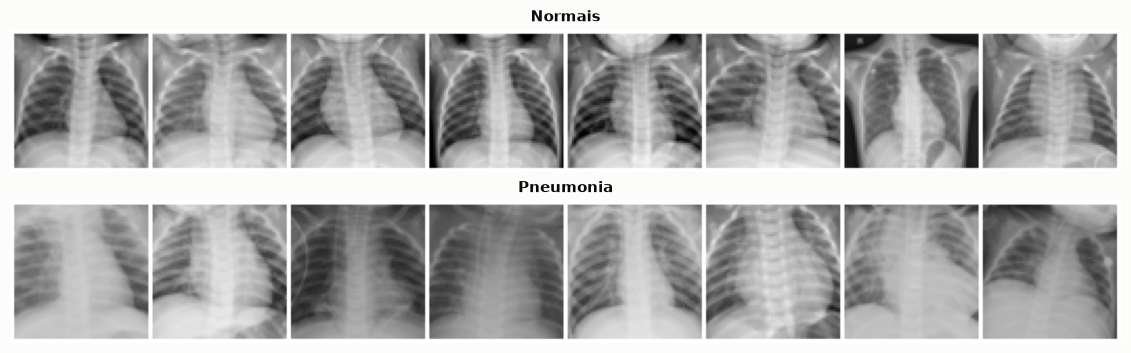

In [6]:
rng = np.random.default_rng(7)
exemplos_n = rng.choice(np.where(y_treino == 0)[0], 8, replace=False)
exemplos_p = rng.choice(np.where(y_treino == 1)[0], 8, replace=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 3.6))
mostrar_grade(x_treino[exemplos_n], 8, axes[0], "Normais")
mostrar_grade(x_treino[exemplos_p], 8, axes[1], "Pneumonia")
plt.tight_layout(); plt.show()

Na pneumonia, regiões do pulmão ficam **mais brancas e opacas** (o ar, que aparece escuro no raio-X, é substituído por líquido/inflamação). A imagem média de cada classe ajuda a ver o padrão:

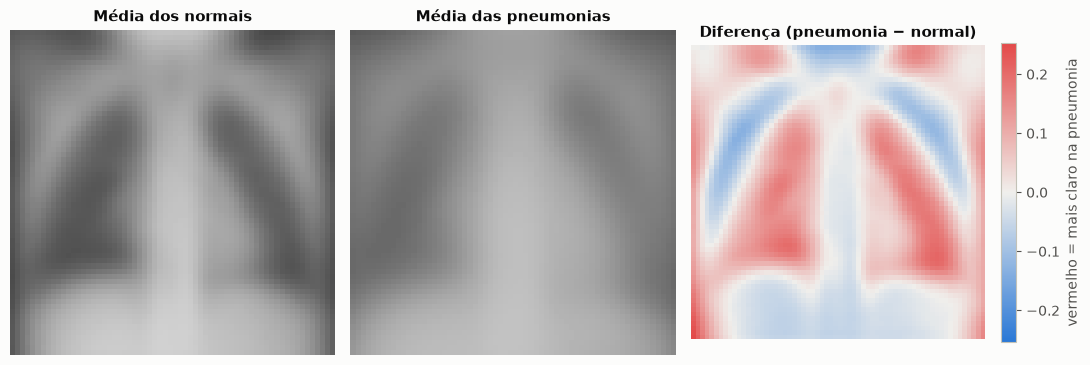

In [7]:
media_n = x_treino[y_treino == 0].mean(0)[0]
media_p = x_treino[y_treino == 1].mean(0)[0]
lim = float((media_p - media_n).abs().max())

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(media_n, cmap="gray", vmin=0, vmax=1); axes[0].set_title("Média dos normais")
axes[1].imshow(media_p, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Média das pneumonias")
im = axes[2].imshow(media_p - media_n, cmap=CMAP_DIVERGENTE, vmin=-lim, vmax=lim)
axes[2].set_title("Diferença (pneumonia − normal)")
for ax in axes: ax.axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.046, label="vermelho = mais claro na pneumonia")
plt.tight_layout(); plt.show()

### 3.1 Montagem dos conjuntos

Este é o ponto central do desenho experimental: **o VAE só vê exames normais no treino**. Os exames com pneumonia do treino são deixados de lado (só a CNN supervisionada da Seção 8.2, usada como referência, os utiliza).

- **Treino do VAE:** os 1.214 exames normais do conjunto de treino.
- **Validação:** acompanhar o treino (normais), calibrar o limiar de decisão (normais) e escolher hiperparâmetros (normais + pneumonias).
- **Teste:** reservado para a avaliação final (234 normais e 390 pneumonias).

In [8]:
x_treino_normal = x_treino[torch.from_numpy(y_treino == 0)]
x_val_normal = x_val[torch.from_numpy(y_val == 0)]
print(f"Treino do VAE: {len(x_treino_normal)} exames normais")
print(f"Validação: {len(x_val)} exames ({len(x_val_normal)} normais)")
print(f"Teste: {len(x_teste)} exames")

Treino do VAE: 1214 exames normais
Validação: 524 exames (135 normais)
Teste: 624 exames


## 4. Arquitetura

### 4.1 Fluxo de dados

```
TREINO (somente exames normais)

 raio-X x        ┌──────────────────┐   μ  (8)   ┌─────────────────┐   ┌──────────────────┐    reconstrução x̂
 1×64×64  ─────► │ Encoder: 4 conv  │ ─────────► │ z = μ + σ ⊙ ε   │ ─►│ Decoder: 4 deconv│ ─► 1×64×64
                 │ 64→32→16→8→4 px  │  log σ² (8)│ ε ~ N(0, I)     │   │ 4→8→16→32→64 px  │
                 └──────────────────┘            └─────────────────┘   └──────────────────┘
 Loss = BCE(x, x̂) + β · KL( N(μ, σ²) ‖ N(0, I) )


USO (qualquer exame)

 raio-X x ─► Encoder ─► μ ─► Decoder ─► x̂          (no uso, z = μ: sem sorteio, resultado determinístico)
    │                                    │
    └──────────► resíduo r = x − x̂ ◄─────┘
                         │
                 suavização gaussiana (σ)        (ver Seção 7: por que suavizar)
                         │
               mapa de calor = r_suave²  ─► score = média do mapa ─► limiar ─► "dentro do padrão" / "revisar"
                                                                  └──────────► posição na fila de triagem
```

### 4.2 Componentes

- **Encoder:** 4 camadas convolucionais com passo 2 (cada uma reduz a imagem pela metade: 64 → 32 → 16 → 8 → 4), com *batch normalization* e ativação LeakyReLU. A saída (256 canais × 4 × 4 = 4.096 números) alimenta duas camadas lineares que produzem $\mu$ e $\log\sigma^2$ (usamos o log da variância por estabilidade numérica).
- **Espaço latente:** 8 dimensões. Com 4.096 pixels de entrada, isso é uma compressão de 512×.
- **Decoder:** o espelho do encoder, com convoluções transpostas que dobram a resolução a cada camada, terminando em uma sigmoide (pixels em [0, 1]).
- **Modo autoencoder comum:** com `deterministico=True`, a mesma rede vira um autoencoder clássico ($z = \mu$, sem KL) — usado como baseline para isolar o efeito da parte variacional.

In [9]:
class VAE(nn.Module):
    def __init__(self, dim_latente=8, deterministico=False):
        super().__init__()
        self.dim_latente = dim_latente
        self.deterministico = deterministico   # True → autoencoder comum (baseline)
        canais = [1, 32, 64, 128, 256]

        camadas = []
        for c_in, c_out in zip(canais[:-1], canais[1:]):
            camadas += [nn.Conv2d(c_in, c_out, kernel_size=4, stride=2, padding=1),
                        nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2)]
        self.encoder = nn.Sequential(*camadas, nn.Flatten())          # → 256×4×4 = 4096
        self.fc_mu = nn.Linear(256 * 4 * 4, dim_latente)
        self.fc_logvar = nn.Linear(256 * 4 * 4, dim_latente)

        self.fc_decoder = nn.Linear(dim_latente, 256 * 4 * 4)
        invertidos = canais[::-1]                                       # 256, 128, 64, 32, 1
        camadas = []
        for c_in, c_out in zip(invertidos[:-2], invertidos[1:-1]):
            camadas += [nn.ConvTranspose2d(c_in, c_out, kernel_size=4, stride=2, padding=1),
                        nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2)]
        camadas += [nn.ConvTranspose2d(invertidos[-2], 1, kernel_size=4, stride=2, padding=1), nn.Sigmoid()]
        self.decoder = nn.Sequential(*camadas)

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparametrizar(self, mu, logvar):
        # Truque da reparametrização: z = μ + σ·ε. Fora do treino (ou no autoencoder comum), usamos z = μ.
        if self.deterministico or not self.training:
            return mu
        eps = torch.randn_like(mu)
        return mu + eps * torch.exp(0.5 * logvar)

    def decode(self, z):
        return self.decoder(self.fc_decoder(z).view(-1, 256, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparametrizar(mu, logvar)
        return self.decode(z), mu, logvar


def termos_da_loss(x, x_rec, mu, logvar):
    # Reconstrução: BCE somada sobre os 4.096 pixels de cada imagem
    reconstrucao = F.binary_cross_entropy(x_rec, x, reduction="none").sum(dim=(1, 2, 3))
    # KL entre N(μ, σ²) e N(0, I), fórmula fechada, somada sobre as dimensões latentes
    kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)
    return reconstrucao, kl

In [10]:
def resumo_arquitetura(modelo):
    modelo = modelo.cpu().eval()
    linhas = []
    with torch.no_grad():
        h = torch.zeros(1, 1, 64, 64)
        linhas.append(("entrada (raio-X)", tuple(h.shape[1:])))
        for camada in modelo.encoder:
            h = camada(h)
            if isinstance(camada, (nn.Conv2d, nn.Flatten)):
                linhas.append((f"encoder · {type(camada).__name__}", tuple(h.shape[1:])))
        linhas.append(("μ e log σ²", (modelo.dim_latente,)))
        z = torch.zeros(1, modelo.dim_latente)
        h = modelo.fc_decoder(z).view(-1, 256, 4, 4)
        linhas.append(("decoder · Linear + reshape", tuple(h.shape[1:])))
        for camada in modelo.decoder:
            h = camada(h)
            if isinstance(camada, nn.ConvTranspose2d):
                linhas.append(("decoder · ConvTranspose2d", tuple(h.shape[1:])))
    for nome, forma in linhas:
        print(f"{nome:<30} {forma}")
    n_params = sum(p.numel() for p in modelo.parameters())
    print(f"\nTotal de parâmetros: {n_params:,}".replace(",", "."))

resumo_arquitetura(VAE(CONFIG["dim_latente"]))

entrada (raio-X)               (1, 64, 64)
encoder · Conv2d               (32, 32, 32)
encoder · Conv2d               (64, 16, 16)
encoder · Conv2d               (128, 8, 8)
encoder · Conv2d               (256, 4, 4)
encoder · Flatten              (4096,)
μ e log σ²                     (8,)
decoder · Linear + reshape     (256, 4, 4)
decoder · ConvTranspose2d      (128, 8, 8)
decoder · ConvTranspose2d      (64, 16, 16)
decoder · ConvTranspose2d      (32, 32, 32)
decoder · ConvTranspose2d      (1, 64, 64)

Total de parâmetros: 1.481.809


## 5. Treinamento

O treino usa o otimizador Adam, lotes de 64 imagens e 40 épocas. Nas primeiras 10 épocas o peso do KL sobe gradualmente de 0 até β (*KL warm-up*), para que o decoder aprenda a reconstruir antes de o espaço latente ser "apertado" — isso reduz o risco de colapso do posterior.

Para servir de comparação, treinamos também um **autoencoder comum** com exatamente a mesma arquitetura e os mesmos dados.

In [11]:
def treinar_autoencoder(semente, dim_latente=None, beta=None, deterministico=False, epocas=None, verbose=True):
    dim_latente = dim_latente or CONFIG["dim_latente"]
    beta = CONFIG["beta"] if beta is None else beta
    epocas = epocas or CONFIG["epocas"]
    fixar_semente(semente)
    modelo = VAE(dim_latente, deterministico).to(DEVICE)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=CONFIG["taxa_aprendizado"])
    x_tr, x_vl = x_treino_normal.to(DEVICE), x_val_normal.to(DEVICE)
    hist = {"rec_treino": [], "kl_treino": [], "rec_val": [], "kl_val": []}
    inicio = time.time()

    for ep in range(epocas):
        modelo.train()
        peso_kl = 0.0 if deterministico else beta * min(1.0, (ep + 1) / CONFIG["epocas_aquecimento_kl"])
        perm = torch.randperm(len(x_tr)).to(DEVICE)
        soma_rec = soma_kl = 0.0
        for i in range(0, len(perm), CONFIG["tamanho_lote"]):
            x = x_tr[perm[i:i + CONFIG["tamanho_lote"]]]
            x_rec, mu, logvar = modelo(x)
            rec, kl = termos_da_loss(x, x_rec, mu, logvar)
            loss = (rec + peso_kl * kl).mean()
            otimizador.zero_grad()
            loss.backward()
            otimizador.step()
            soma_rec += rec.sum().item()
            soma_kl += kl.sum().item()
        hist["rec_treino"].append(soma_rec / len(x_tr))
        hist["kl_treino"].append(soma_kl / len(x_tr))

        modelo.eval()
        with torch.no_grad():
            x_rec, mu, logvar = modelo(x_vl)
            rec, kl = termos_da_loss(x_vl, x_rec, mu, logvar)
        hist["rec_val"].append(rec.mean().item())
        hist["kl_val"].append(kl.mean().item())
        if verbose and (ep + 1) % 10 == 0:
            print(f"  época {ep + 1:3d} | reconstrução {hist['rec_treino'][-1]:7.1f} | "
                  f"KL {hist['kl_treino'][-1]:5.1f} | reconstrução (val) {hist['rec_val'][-1]:7.1f}")

    modelo.eval()
    if verbose:
        print(f"  tempo de treino: {time.time() - inicio:.0f}s")
    return modelo, hist


print("VAE (semente 0)")
vae, hist_vae = treinar_autoencoder(semente=0)
print("\nAutoencoder comum (semente 0) — mesma arquitetura, sem a parte variacional")
ae, hist_ae = treinar_autoencoder(semente=0, deterministico=True)

VAE (semente 0)


  época  10 | reconstrução  2557.0 | KL  14.3 | reconstrução (val)  2539.4


  época  20 | reconstrução  2550.2 | KL  14.2 | reconstrução (val)  2539.5


  época  30 | reconstrução  2548.1 | KL  14.5 | reconstrução (val)  2535.8


  época  40 | reconstrução  2544.4 | KL  14.4 | reconstrução (val)  2532.3
  tempo de treino: 17s

Autoencoder comum (semente 0) — mesma arquitetura, sem a parte variacional


  época  10 | reconstrução  2556.0 | KL 124.3 | reconstrução (val)  2543.3


  época  20 | reconstrução  2545.7 | KL 155.9 | reconstrução (val)  2535.4


  época  30 | reconstrução  2541.5 | KL 183.9 | reconstrução (val)  2532.6


  época  40 | reconstrução  2538.8 | KL 210.9 | reconstrução (val)  2531.3
  tempo de treino: 17s


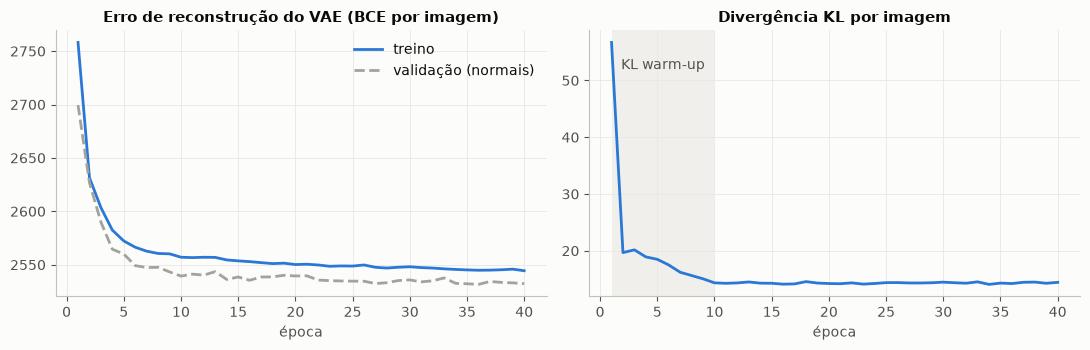

In [12]:
ep = np.arange(1, CONFIG["epocas"] + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ep, hist_vae["rec_treino"], color=COR_NORMAL, label="treino")
axes[0].plot(ep, hist_vae["rec_val"], color=COR_NEUTRA, linestyle="--", label="validação (normais)")
axes[0].set_title("Erro de reconstrução do VAE (BCE por imagem)")
axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(ep, hist_vae["kl_treino"], color=COR_NORMAL)
axes[1].axvspan(1, CONFIG["epocas_aquecimento_kl"], color="#e8e7e3", alpha=0.6, lw=0)
axes[1].text(CONFIG["epocas_aquecimento_kl"] / 2 + 0.5, max(hist_vae["kl_treino"]) * 0.95,
             "KL warm-up", ha="center", va="top", color=COR_TEXTO_2)
axes[1].set_title("Divergência KL por imagem")
axes[1].set_xlabel("época")
plt.tight_layout(); plt.show()

**Leitura:** o erro de reconstrução cai rápido nas primeiras épocas e se estabiliza; as curvas de treino e validação ficam próximas, sem sinal de *overfitting* (a de validação fica até um pouco abaixo porque, na avaliação, usamos $z = \mu$, sem o ruído do sorteio). O KL é alto no início — quando seu peso ainda é zero, os códigos ficam livres — e cai à medida que o warm-up passa a "puxar" os códigos para perto de $\mathcal{N}(0, I)$.

## 6. O que o VAE aprendeu

Antes de usar o VAE como detector, vale olhar o que ele aprendeu: como reconstrói, o que gera e como organiza o espaço latente.

In [13]:
@torch.no_grad()
def reconstruir(modelo, x, lote=256):
    modelo.eval()
    return torch.cat([modelo(x[i:i + lote].to(DEVICE))[0].cpu() for i in range(0, len(x), lote)])

@torch.no_grad()
def codificar(modelo, x, lote=256):
    modelo.eval()
    mus, logvars = [], []
    for i in range(0, len(x), lote):
        mu, logvar = modelo.encode(x[i:i + lote].to(DEVICE))
        mus.append(mu.cpu()); logvars.append(logvar.cpu())
    return torch.cat(mus), torch.cat(logvars)

@torch.no_grad()
def decodificar(modelo, z):
    modelo.eval()
    return modelo.decode(z.to(DEVICE)).cpu()

rec_vae = {"val": reconstruir(vae, x_val), "teste": reconstruir(vae, x_teste)}
rec_ae = {"val": reconstruir(ae, x_val), "teste": reconstruir(ae, x_teste)}

rng = np.random.default_rng(42)
idx_n = rng.choice(np.where(y_teste == 0)[0], 6, replace=False)
idx_p = rng.choice(np.where(y_teste == 1)[0], 6, replace=False)

### 6.1 Reconstruções

Linha de cima: exame original (conjunto de teste, que o modelo nunca viu). Linha de baixo: reconstrução do VAE.

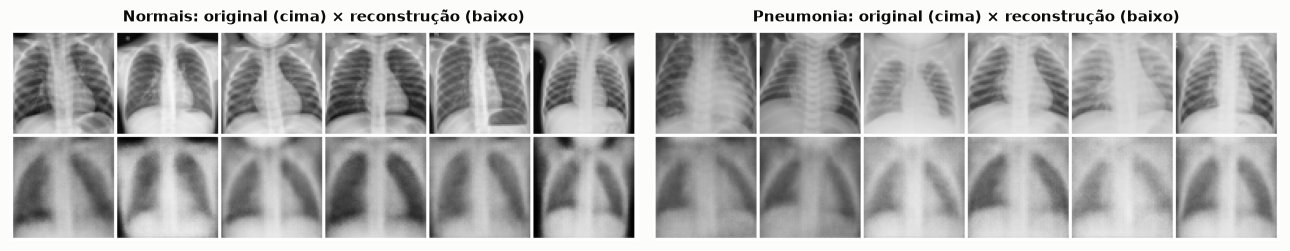

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
mostrar_grade(torch.cat([x_teste[idx_n], rec_vae["teste"][idx_n]]), 6, axes[0], "Normais: original (cima) × reconstrução (baixo)")
mostrar_grade(torch.cat([x_teste[idx_p], rec_vae["teste"][idx_p]]), 6, axes[1], "Pneumonia: original (cima) × reconstrução (baixo)")
plt.tight_layout(); plt.show()

**Leitura:** as reconstruções preservam o formato geral do tórax, mas são **borradas** — a limitação clássica do VAE (Seção 1.4). Nos exames com pneumonia, a reconstrução tende a "limpar" as opacidades e devolver um pulmão com cara de normal: é exatamente esse comportamento que queremos explorar para detectar anomalias.

### 6.2 Geração de raios-X sintéticos: VAE × autoencoder comum

Sorteamos 16 vetores $z \sim \mathcal{N}(0, I)$ e passamos pelo decoder. No VAE, o termo KL garante que essa região do espaço latente esteja "povoada"; no autoencoder comum, não há essa garantia.

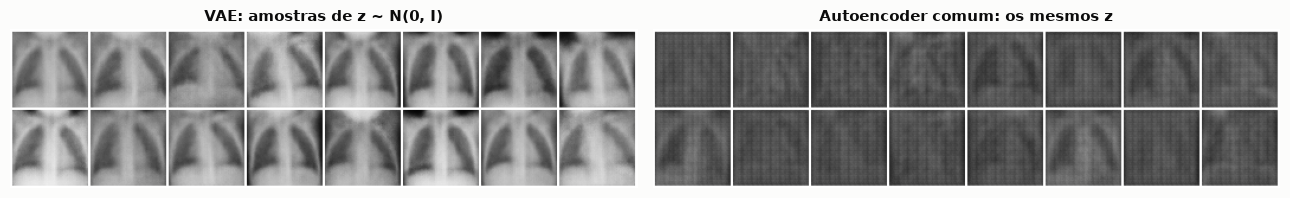

,z0,z1,z2,z3,z4,z5,z6,z7
desvio de μ (VAE),1.10,1.14,1.10,1.04,1.04,1.32,1.10,1.11
desvio de z (autoencoder comum),7.14,6.53,7.95,5.00,5.93,5.46,5.78,5.52
KL média (VAE),1.77,1.85,1.82,1.46,1.61,2.42,2.30,1.79


Dimensões ativas do VAE (KL média > 0,1): 8 de 8


In [15]:
fixar_semente(123)
z = torch.randn(16, CONFIG["dim_latente"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
mostrar_grade(decodificar(vae, z), 8, axes[0], "VAE: amostras de z ~ N(0, I)")
mostrar_grade(decodificar(ae, z), 8, axes[1], "Autoencoder comum: os mesmos z")
plt.tight_layout(); plt.show()

mu_vae, logvar_vae = codificar(vae, x_treino_normal)
mu_ae, _ = codificar(ae, x_treino_normal)
kl_por_dim = (-0.5 * (1 + logvar_vae - mu_vae.pow(2) - logvar_vae.exp())).mean(0)
tabela_latente = pd.DataFrame({
    "desvio de μ (VAE)": mu_vae.std(0).numpy(),
    "desvio de z (autoencoder comum)": mu_ae.std(0).numpy(),
    "KL média (VAE)": kl_por_dim.numpy(),
}, index=[f"z{j}" for j in range(CONFIG["dim_latente"])]).round(2)
display(tabela_latente.T)
print(f"Dimensões ativas do VAE (KL média > 0,1): {(kl_por_dim > 0.1).sum().item()} de {CONFIG['dim_latente']}")

**Leitura:** as amostras do VAE parecem raios-X de tórax plausíveis (borrados, mas com pulmões, mediastino e diafragma no lugar); as do autoencoder comum são basicamente ruído. A tabela explica por quê: no VAE, os códigos de cada dimensão ficam numa escala próxima de 1 — compatível com sortear de $\mathcal{N}(0, I)$. No autoencoder comum a escala é arbitrária (bem maior), então sortear de $\mathcal{N}(0, I)$ cai numa região minúscula e "vazia" do espaço latente, que o decoder nunca viu.

A linha de KL por dimensão mostra quantas dimensões o VAE realmente usa: uma dimensão com KL ≈ 0 teria sido "desligada" (colapso do posterior). Com um espaço latente pequeno como este, é normal que todas fiquem ativas.

### 6.3 Percorrendo o espaço latente

Cada linha varia **uma** das 8 dimensões de −3 a +3, mantendo as outras em zero. Isso mostra que tipo de variação cada dimensão aprendeu a representar.

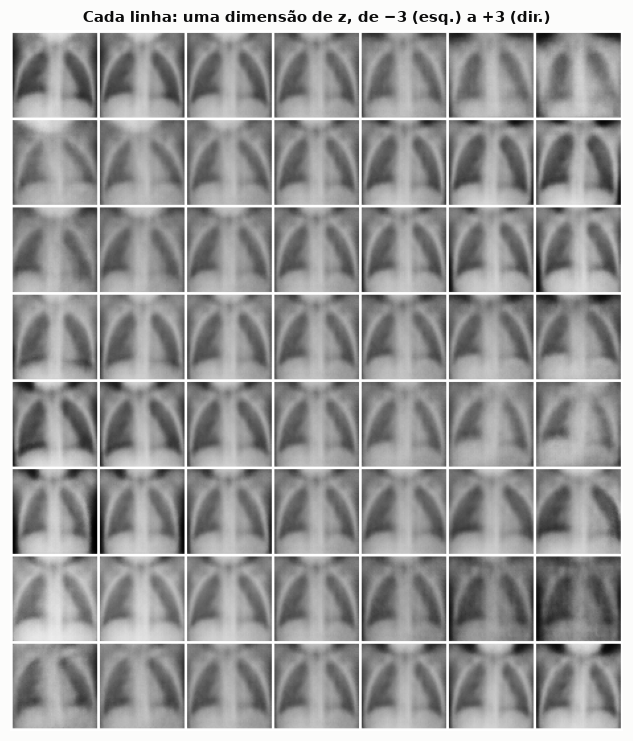

In [16]:
valores = torch.linspace(-3, 3, 7)
z = torch.zeros(CONFIG["dim_latente"] * len(valores), CONFIG["dim_latente"])
for d in range(CONFIG["dim_latente"]):
    z[d * len(valores):(d + 1) * len(valores), d] = valores
fig, ax = plt.subplots(figsize=(6.5, 7.5))
mostrar_grade(decodificar(vae, z), len(valores), ax, "Cada linha: uma dimensão de z, de −3 (esq.) a +3 (dir.)")
plt.tight_layout(); plt.show()

**Leitura:** cada dimensão codifica uma variação **global** — brilho e contraste geral, tamanho e posição do tórax, áreas escuras nas bordas da imagem, quanto os campos pulmonares aparecem escuros. São justamente as variações "normais" entre exames. Nenhuma dimensão representa uma opacidade localizada, porque o VAE nunca viu uma.

### 6.4 Interpolação entre dois exames

Codificamos um exame normal e um com pneumonia, e decodificamos pontos intermediários no espaço latente.

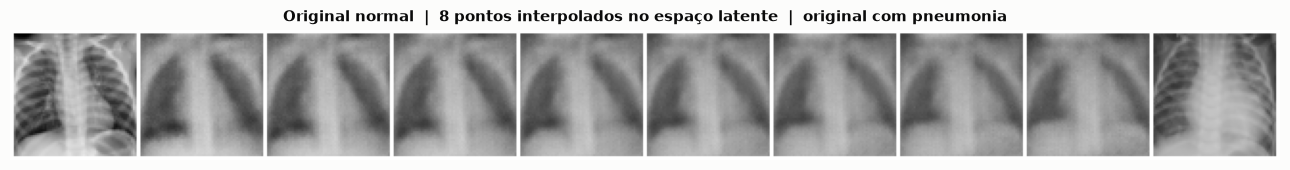

In [17]:
i_a, i_b = idx_n[0], idx_p[0]
mu_ab, _ = codificar(vae, x_teste[[i_a, i_b]])
t = torch.linspace(0, 1, 8).unsqueeze(1)
z = (1 - t) * mu_ab[0] + t * mu_ab[1]
caminho = torch.cat([x_teste[[i_a]], decodificar(vae, z), x_teste[[i_b]]])
fig, ax = plt.subplots(figsize=(13, 2.2))
mostrar_grade(caminho, 10, ax, "Original normal  |  8 pontos interpolados no espaço latente  |  original com pneumonia")
plt.tight_layout(); plt.show()

**Leitura:** a transição é suave — sinal de um espaço latente contínuo. Note que mesmo a ponta "pneumonia" da interpolação não reproduz as opacidades do exame original: o decoder só sabe desenhar pulmões normais.

### 6.5 Mapa do espaço latente

Projetamos os códigos $\mu$ (8 dimensões) dos exames de teste em 2 dimensões com PCA, coloridos pelo rótulo verdadeiro — que o VAE **nunca viu**.

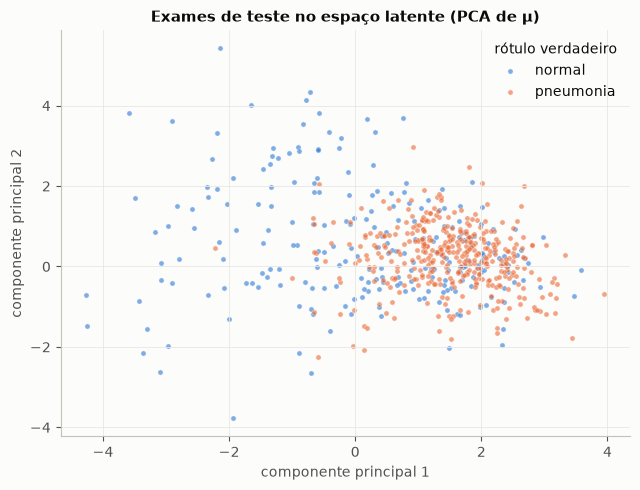

In [18]:
mu_teste, _ = codificar(vae, x_teste)
proj = PCA(2).fit(mu_vae.numpy())   # eixos definidos só com os normais do treino
p2 = proj.transform(mu_teste.numpy())
fig, ax = plt.subplots(figsize=(6.5, 5))
for classe, cor, nome in [(0, COR_NORMAL, "normal"), (1, COR_PNEU, "pneumonia")]:
    m = y_teste == classe
    ax.scatter(p2[m, 0], p2[m, 1], s=14, color=cor, alpha=0.6, edgecolors="#fcfcfb", linewidths=0.4, label=nome)
ax.set_xlabel("componente principal 1"); ax.set_ylabel("componente principal 2")
ax.set_title("Exames de teste no espaço latente (PCA de μ)")
ax.legend(title="rótulo verdadeiro")
plt.tight_layout(); plt.show()

**Leitura:** os exames normais se espalham por todo o espaço latente, enquanto as pneumonias se concentram numa região compacta — **dentro** da área ocupada pelos normais. Para o encoder, um exame com pneumonia parece um "normal típico" (um primeiro indício de que as pneumonias são, em certo sentido, imagens mais *simples*; Seção 7.2). Por isso, a posição no espaço latente não serve como score de anomalia; usamos o **erro de reconstrução**, na próxima seção.

## 7. Do erro de reconstrução ao score de anomalia

A métrica principal para avaliar o score é a **AUC-ROC**: a probabilidade de um exame com pneumonia, sorteado ao acaso, receber score maior que um normal sorteado ao acaso. AUC = 1 é separação perfeita; AUC = 0,5 é o mesmo que sortear; **AUC < 0,5 significa que o score está invertido**.

In [19]:
def suavizar(img, sigma):
    if sigma <= 0:
        return img
    k = int(4 * sigma) | 1   # tamanho de kernel ímpar ≈ 4σ
    return TF.gaussian_blur(img, kernel_size=k, sigma=sigma)

def mapa_de_anomalia(x, x_rec, sigma):
    # Resíduo (original − reconstrução), suavizado e elevado ao quadrado, pixel a pixel
    return suavizar(x - x_rec, sigma) ** 2

def score_de_anomalia(x, x_rec, sigma):
    # Score = média do mapa de anomalia. Com σ = 0, é o erro quadrático médio comum.
    return mapa_de_anomalia(x, x_rec, sigma).mean(dim=(1, 2, 3)).numpy()

def auc(y, score):
    return roc_auc_score(y, score)

### 7.1 Primeira tentativa: erro de reconstrução pixel a pixel

A ideia direta: score = erro quadrático médio entre o exame e sua reconstrução. Exames com pneumonia, que o VAE "não sabe" reconstruir, deveriam ter erro maior.

AUC do erro pixel a pixel — validação: 0.763 | teste: 0.617


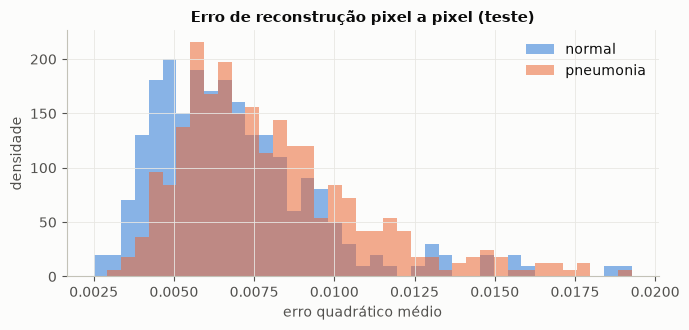

In [20]:
score_ingenuo_val = score_de_anomalia(x_val, rec_vae["val"], sigma=0)
score_ingenuo_teste = score_de_anomalia(x_teste, rec_vae["teste"], sigma=0)
print(f"AUC do erro pixel a pixel — validação: {auc(y_val, score_ingenuo_val):.3f} | teste: {auc(y_teste, score_ingenuo_teste):.3f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(score_ingenuo_teste.min(), np.percentile(score_ingenuo_teste, 99.5), 40)
for classe, cor, nome in [(0, COR_NORMAL, "normal"), (1, COR_PNEU, "pneumonia")]:
    ax.hist(score_ingenuo_teste[y_teste == classe], bins=bins, color=cor, alpha=0.55, density=True, label=nome)
ax.set_title("Erro de reconstrução pixel a pixel (teste)")
ax.set_xlabel("erro quadrático médio"); ax.set_ylabel("densidade"); ax.legend()
plt.tight_layout(); plt.show()

**O resultado é fraco:** as duas distribuições quase se sobrepõem, e no teste a AUC fica perto do acaso. O VAE reconstrói exames com pneumonia quase tão bem quanto os normais — e às vezes melhor.

### 7.2 Por que a versão ingênua falha

O resíduo $r = x - \hat{x}$ mistura duas coisas de natureza diferente:

- **Baixa frequência** (regiões inteiras mais claras ou mais escuras que o esperado): é aqui que uma opacidade de pneumonia deveria aparecer.
- **Alta frequência** (detalhe fino: bordas de costelas, vasos): o VAE perde esse detalhe em *todos* os exames, porque suas reconstruções são borradas (Seção 1.4).

Hipótese: os exames com pneumonia têm **menos detalhe fino** (a opacidade "apaga" vasos e bordas). Nesse caso, a parte de alta frequência do erro seria *maior nos normais* — o contrário do que queremos — e cancelaria parte do sinal útil.

Para testar, separamos o resíduo nas duas partes (com uma suavização gaussiana de 3 pixels) e medimos a AUC de cada uma. Também medimos o **nível de detalhe** de cada imagem original: $|x - \text{suavizar}(x)|$, em média sobre os pixels.

,AUC validação,AUC teste
erro total (pixel a pixel),0.763,0.617
parte de alta frequência (detalhe fino),0.214,0.195
parte de baixa frequência (regiões),0.905,0.822


Detalhe médio — normais: 0.0310 | pneumonia: 0.0204
Correlação (Spearman) entre o erro de alta frequência e o nível de detalhe da imagem: 0.91
AUC de 'menos detalhe = pneumonia', sem modelo nenhum: 0.906


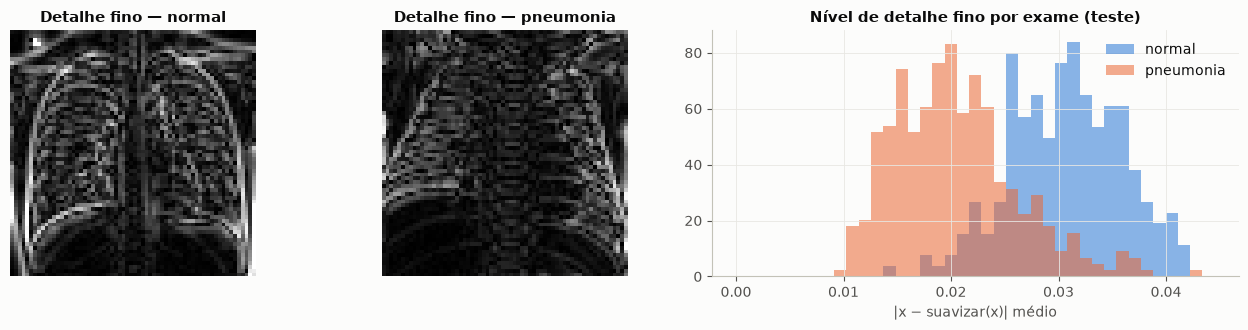

In [21]:
def nivel_de_detalhe(x, sigma=1.5):
    return (x - suavizar(x, sigma)).abs().mean(dim=(1, 2, 3)).numpy()

def energia_baixa_freq(r, sigma=3):
    return (suavizar(r, sigma) ** 2).mean(dim=(1, 2, 3)).numpy()

def energia_alta_freq(r, sigma=3):
    return ((r - suavizar(r, sigma)) ** 2).mean(dim=(1, 2, 3)).numpy()

residuo_val, residuo_teste = x_val - rec_vae["val"], x_teste - rec_vae["teste"]
display(pd.DataFrame({
    "AUC validação": [auc(y_val, score_ingenuo_val), auc(y_val, energia_alta_freq(residuo_val)),
                      auc(y_val, energia_baixa_freq(residuo_val))],
    "AUC teste": [auc(y_teste, score_ingenuo_teste), auc(y_teste, energia_alta_freq(residuo_teste)),
                  auc(y_teste, energia_baixa_freq(residuo_teste))],
}, index=["erro total (pixel a pixel)", "parte de alta frequência (detalhe fino)",
          "parte de baixa frequência (regiões)"]).round(3))

detalhe_teste = nivel_de_detalhe(x_teste)
rho, _ = spearmanr(energia_alta_freq(residuo_teste), detalhe_teste)
print(f"Detalhe médio — normais: {detalhe_teste[y_teste == 0].mean():.4f} | pneumonia: {detalhe_teste[y_teste == 1].mean():.4f}")
print(f"Correlação (Spearman) entre o erro de alta frequência e o nível de detalhe da imagem: {rho:.2f}")
print(f"AUC de 'menos detalhe = pneumonia', sem modelo nenhum: {auc(y_teste, -detalhe_teste):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1, 1, 1.6]})
for ax, i, nome in [(axes[0], idx_n[1], "normal"), (axes[1], idx_p[1], "pneumonia")]:
    alta_freq = (x_teste[i] - suavizar(x_teste[i:i + 1], 1.5)[0])[0].abs()
    ax.imshow(alta_freq, cmap="gray", vmin=0, vmax=0.15); ax.axis("off")
    ax.set_title(f"Detalhe fino — {nome}")
bins = np.linspace(0, np.percentile(detalhe_teste, 99.5), 40)
for classe, cor, nome in [(0, COR_NORMAL, "normal"), (1, COR_PNEU, "pneumonia")]:
    axes[2].hist(detalhe_teste[y_teste == classe], bins=bins, color=cor, alpha=0.55, density=True, label=nome)
axes[2].set_title("Nível de detalhe fino por exame (teste)")
axes[2].set_xlabel("|x − suavizar(x)| médio"); axes[2].legend()
plt.tight_layout(); plt.show()

**Confirmado:**

- A parte de **alta frequência** do erro tem AUC muito **abaixo de 0,5** — ela é *maior nos normais*. Ela acompanha o nível de detalhe da imagem: os normais têm mais detalhe fino, e o VAE perde esse detalhe ao reconstruir.
- A parte de **baixa frequência** carrega o sinal da anomalia, com AUC alta.
- No erro total, as duas partes se somam e **se cancelam parcialmente** — por isso o score ingênuo é fraco.

É uma versão do fenômeno descrito por Nalisnick et al. (2019) e Serrà et al. (2020): para modelos generativos, **imagens mais simples parecem mais "normais"**.

> **Atenção:** a última linha acima mostra que, *neste conjunto de dados*, uma heurística de uma linha (nível de detalhe) separa as classes muito bem. Só descobrimos isso olhando os rótulos de pneumonia — ou seja, não é algo que um detector de anomalias "genérico" saberia de antemão. Voltamos a isso na Seção 9.

### 7.3 A correção: comparar em baixa frequência

Se o problema é o detalhe fino (que o VAE perde em *todos* os exames), a solução é **ignorá-lo**: suavizamos o resíduo $x - \hat{x}$ com um filtro gaussiano de largura σ antes de medir o erro. Sobram as diferenças de **grande escala** — regiões inteiras mais brancas ou mais escuras que o "normal" reconstruído —, que é como uma opacidade de pneumonia aparece.

A largura σ é escolhida pela AUC no conjunto de **validação** (o teste fica intocado).

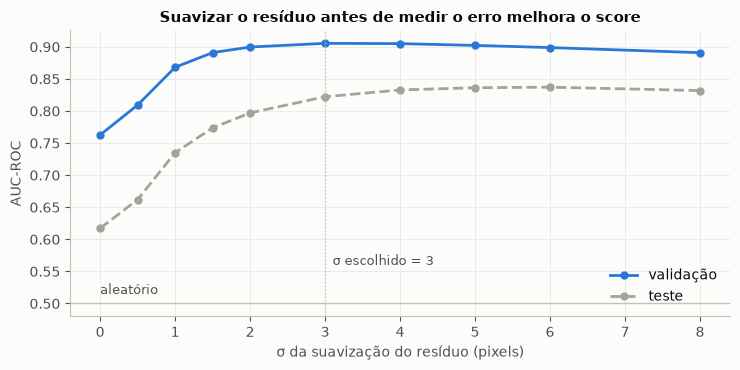

σ escolhido na validação: 3
AUC com σ = 3 — validação: 0.905 | teste: 0.822


In [22]:
SIGMAS = [0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 8]
auc_sigma_val = [auc(y_val, score_de_anomalia(x_val, rec_vae["val"], s)) for s in SIGMAS]
auc_sigma_teste = [auc(y_teste, score_de_anomalia(x_teste, rec_vae["teste"], s)) for s in SIGMAS]
SIGMA = SIGMAS[int(np.argmax(auc_sigma_val))]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(SIGMAS, auc_sigma_val, marker="o", markersize=5, color=COR_NORMAL, label="validação")
ax.plot(SIGMAS, auc_sigma_teste, marker="o", markersize=5, color=COR_NEUTRA, linestyle="--", label="teste")
ax.axhline(0.5, color="#c3c2b7", lw=1)
ax.text(SIGMAS[0], 0.51, "aleatório", ha="left", va="bottom", color=COR_TEXTO_2, fontsize=9)
ax.axvline(SIGMA, color="#c3c2b7", lw=1, linestyle=":")
ax.text(SIGMA + 0.1, 0.56, f"σ escolhido = {SIGMA}", color=COR_TEXTO_2, fontsize=9)
ax.set_xlabel("σ da suavização do resíduo (pixels)"); ax.set_ylabel("AUC-ROC")
ax.set_title("Suavizar o resíduo antes de medir o erro melhora o score"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"σ escolhido na validação: {SIGMA}")
print(f"AUC com σ = {SIGMA} — validação: {auc_sigma_val[SIGMAS.index(SIGMA)]:.3f} | teste: {auc_sigma_teste[SIGMAS.index(SIGMA)]:.3f}")

**Leitura:** com σ = 0 (erro pixel a pixel) a AUC é baixa — no teste, perto do acaso. À medida que σ cresce, o detalhe fino deixa de contar e a AUC sobe bastante, até estabilizar a partir de σ ≈ 3. A partir daqui, o **score de anomalia** é sempre a média do resíduo suavizado ao quadrado, com o σ escolhido na validação.

### 7.4 Mapas de calor

O mapa de calor é o resíduo suavizado ao quadrado, pixel a pixel — o score é exatamente a média desse mapa. A escala de cor é **a mesma para todos os exames** (normalizar por exame faria qualquer exame parecer "quente").

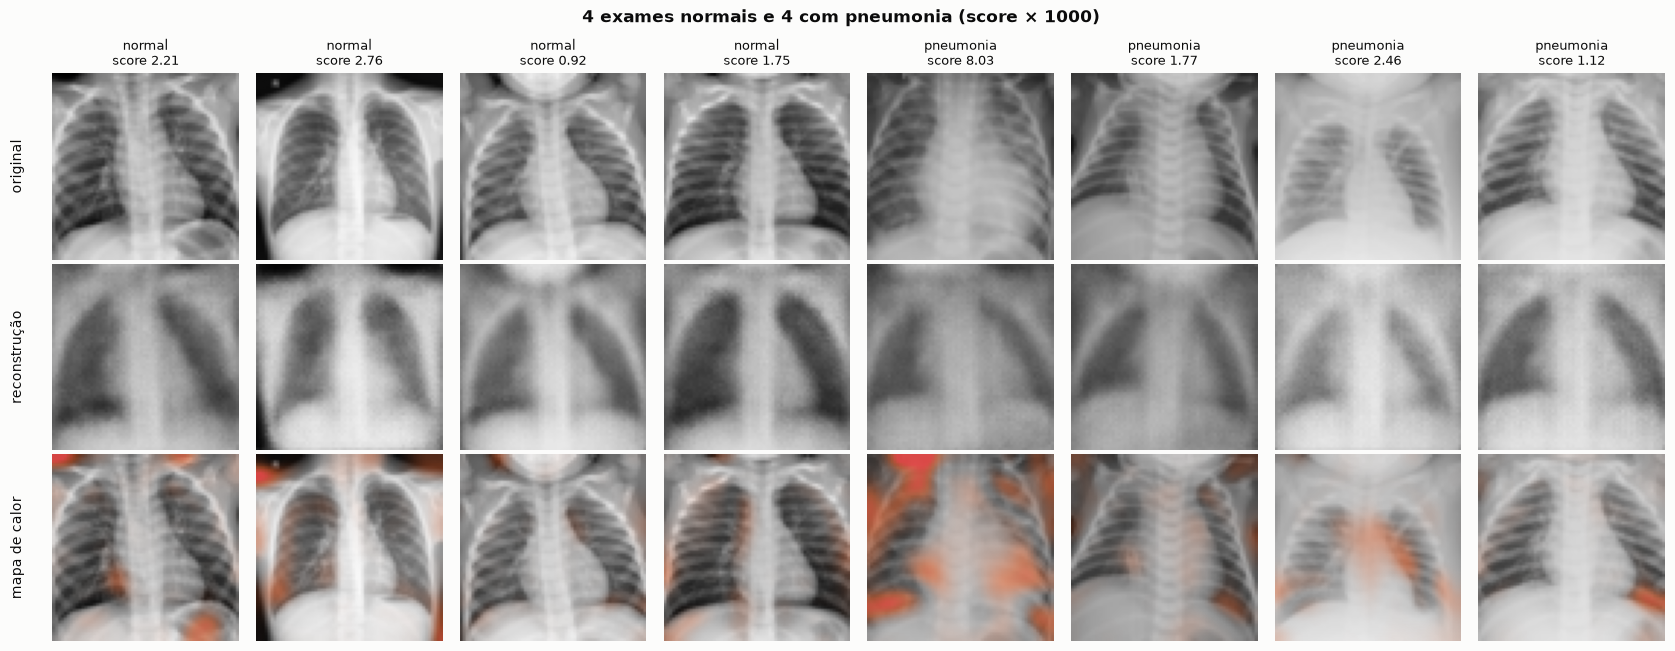

In [23]:
mapas_teste = mapa_de_anomalia(x_teste, rec_vae["teste"], SIGMA)
score_teste = mapas_teste.mean(dim=(1, 2, 3)).numpy()
VMAX_MAPA = float(np.percentile(mapas_teste.numpy(), 99.5))

def painel_exames(indices, titulo):
    fig, axes = plt.subplots(3, len(indices), figsize=(2.1 * len(indices), 6.6))
    for c, i in enumerate(indices):
        rotulo = "pneumonia" if y_teste[i] == 1 else "normal"
        axes[0, c].imshow(x_teste[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[0, c].set_title(f"{rotulo}\nscore {score_teste[i] * 1e3:.2f}", fontsize=9, fontweight="normal")
        axes[1, c].imshow(rec_vae["teste"][i, 0], cmap="gray", vmin=0, vmax=1)
        axes[2, c].imshow(x_teste[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[2, c].imshow(mapas_teste[i, 0], cmap=CMAP_CALOR, vmin=0, vmax=VMAX_MAPA)
        for r in range(3):
            axes[r, c].axis("off")
    axes[0, 0].text(-0.15, 0.5, "original", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
    axes[1, 0].text(-0.15, 0.5, "reconstrução", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
    axes[2, 0].text(-0.15, 0.5, "mapa de calor", transform=axes[2, 0].transAxes, rotation=90, va="center", ha="right")
    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout(); plt.show()

painel_exames(list(idx_n[:4]) + list(idx_p[:4]), "4 exames normais e 4 com pneumonia (score × 1000)")

**Leitura:** em parte das pneumonias, o mapa acende **dentro dos campos pulmonares**, onde o exame está mais branco que o "normal" reconstruído. Mas o mapa também acende em cantos da imagem, no diafragma e no abdômen — inclusive em exames normais —, onde o enquadramento varia de exame para exame. E há sobreposição: algumas pneumonias recebem score menor que alguns normais. Esses erros são analisados na Seção 9.

## 8. Avaliação experimental

### 8.1 Desempenho do VAE no conjunto de teste

Métricas:

- **AUC-ROC:** separação geral, independente de limiar.
- **AP (precisão média, área sob a curva precisão × revocação):** mais informativa quando as classes são desbalanceadas. Atenção: a AP de um score aleatório é igual à proporção de positivos — aqui, 62,5% —, não 0,5.

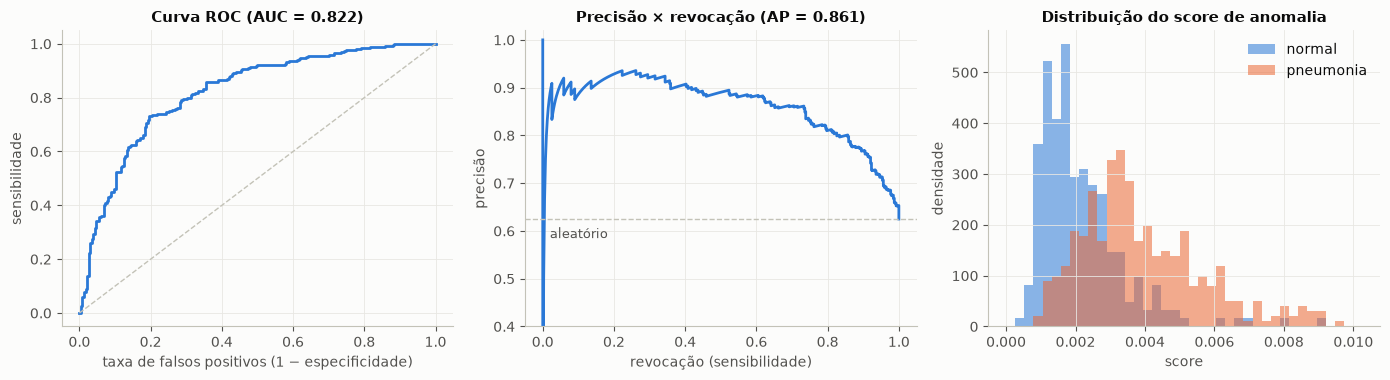

In [24]:
fpr, tpr, _ = roc_curve(y_teste, score_teste)
prec, rev, _ = precision_recall_curve(y_teste, score_teste)
auc_teste, ap_teste = auc(y_teste, score_teste), average_precision_score(y_teste, score_teste)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
axes[0].plot(fpr, tpr, color=COR_NORMAL)
axes[0].plot([0, 1], [0, 1], color="#c3c2b7", lw=1, linestyle="--")
axes[0].set_title(f"Curva ROC (AUC = {auc_teste:.3f})")
axes[0].set_xlabel("taxa de falsos positivos (1 − especificidade)"); axes[0].set_ylabel("sensibilidade")
axes[1].plot(rev, prec, color=COR_NORMAL)
axes[1].axhline(y_teste.mean(), color="#c3c2b7", lw=1, linestyle="--")
axes[1].text(0.02, y_teste.mean() - 0.04, "aleatório", color=COR_TEXTO_2, fontsize=9)
axes[1].set_title(f"Precisão × revocação (AP = {ap_teste:.3f})")
axes[1].set_xlabel("revocação (sensibilidade)"); axes[1].set_ylabel("precisão"); axes[1].set_ylim(0.4, 1.02)
bins = np.linspace(0, np.percentile(score_teste, 99), 40)
for classe, cor, nome in [(0, COR_NORMAL, "normal"), (1, COR_PNEU, "pneumonia")]:
    axes[2].hist(score_teste[y_teste == classe], bins=bins, color=cor, alpha=0.55, density=True, label=nome)
axes[2].set_title("Distribuição do score de anomalia"); axes[2].set_xlabel("score")
axes[2].set_ylabel("densidade"); axes[2].legend()
plt.tight_layout(); plt.show()

### 8.2 Comparação com alternativas

Para saber se o VAE acrescenta algo, comparamos com alternativas, todas avaliadas do mesmo jeito (mesmo score suavizado, com σ escolhido na validação **para cada método**):

**Sem rótulos de pneumonia (mesmas condições do VAE):**

| Método | O que é |
|---|---|
| Brilho médio | Score = brilho médio da imagem. Testa se "imagem mais branca" já resolve. |
| Imagem média | "Reconstrução" = imagem média dos normais de treino. Testa se um modelo é necessário. |
| PCA (8 componentes) | O "autoencoder linear" clássico, com o mesmo tamanho de código. |
| Autoencoder comum | Mesma rede do VAE, sem a parte variacional. Isola o efeito do "V". |
| **VAE** | Nossa proposta. |

**Com rótulos de pneumonia (referências, condições mais favoráveis):**

| Método | O que é |
|---|---|
| Nível de detalhe | A heurística da Seção 7.2 ("menos detalhe fino = pneumonia"), descoberta olhando os rótulos. |
| CNN supervisionada | Mesmo encoder do VAE + uma camada de classificação, treinada com normais **e** pneumonias. É o "teto" esperado. |

Autoencoder comum e VAE são treinados com 3 sementes diferentes; reportamos média ± desvio-padrão.

In [25]:
def avaliar_reconstrucoes(rec_val, rec_teste):
    # Escolhe σ pela AUC de validação e avalia no teste com esse σ
    aucs_val = {s: auc(y_val, score_de_anomalia(x_val, rec_val, s)) for s in SIGMAS}
    s = max(aucs_val, key=aucs_val.get)
    sc = score_de_anomalia(x_teste, rec_teste, s)
    return {"σ": s, "AUC val": aucs_val[s], "AUC teste": auc(y_teste, sc), "AP teste": average_precision_score(y_teste, sc)}

def avaliar_score(score_val, score_teste_):
    return {"σ": None, "AUC val": auc(y_val, score_val), "AUC teste": auc(y_teste, score_teste_),
            "AP teste": average_precision_score(y_teste, score_teste_)}

resultados = {}

# Brilho médio
resultados["Brilho médio"] = [avaliar_score(x_val.mean(dim=(1, 2, 3)).numpy(), x_teste.mean(dim=(1, 2, 3)).numpy())]

# Imagem média dos normais como "reconstrução"
media_normais = x_treino_normal.mean(0, keepdim=True)
resultados["Imagem média"] = [avaliar_reconstrucoes(media_normais.expand_as(x_val), media_normais.expand_as(x_teste))]

# PCA com o mesmo tamanho de código do VAE
pca = PCA(CONFIG["dim_latente"]).fit(x_treino_normal.flatten(1).numpy())
def reconstruir_pca(x):
    return torch.tensor(pca.inverse_transform(pca.transform(x.flatten(1).numpy())), dtype=torch.float32).view_as(x)
resultados[f"PCA ({CONFIG['dim_latente']} componentes)"] = [avaliar_reconstrucoes(reconstruir_pca(x_val), reconstruir_pca(x_teste))]

# Autoencoder comum e VAE, várias sementes (a semente 0 já foi treinada)
modelos_ae, modelos_vae = {0: ae}, {0: vae}
for s in CONFIG["sementes"]:
    if s not in modelos_ae:
        print(f"Treinando autoencoder comum e VAE com semente {s}...")
        modelos_ae[s], _ = treinar_autoencoder(semente=s, deterministico=True, verbose=False)
        modelos_vae[s], _ = treinar_autoencoder(semente=s, verbose=False)
resultados["Autoencoder comum"] = [avaliar_reconstrucoes(reconstruir(m, x_val), reconstruir(m, x_teste)) for m in modelos_ae.values()]
resultados["VAE"] = [avaliar_reconstrucoes(reconstruir(m, x_val), reconstruir(m, x_teste)) for m in modelos_vae.values()]

# Heurística de detalhe (descoberta com rótulos)
resultados["Nível de detalhe*"] = [avaliar_score(-nivel_de_detalhe(x_val), -detalhe_teste)]

Treinando autoencoder comum e VAE com semente 1...


Treinando autoencoder comum e VAE com semente 2...


In [26]:
def treinar_cnn_supervisionada(semente=0, epocas=8):
    fixar_semente(semente)
    canais = [1, 32, 64, 128, 256]
    camadas = []
    for c_in, c_out in zip(canais[:-1], canais[1:]):
        camadas += [nn.Conv2d(c_in, c_out, 4, 2, 1), nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2)]
    modelo = nn.Sequential(*camadas, nn.Flatten(), nn.Dropout(0.3), nn.Linear(256 * 4 * 4, 1)).to(DEVICE)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    # Compensa o desbalanceamento (há ~3× mais pneumonias que normais no treino)
    peso_pos = torch.tensor([(y_treino == 0).sum() / (y_treino == 1).sum()], dtype=torch.float32, device=DEVICE)
    x_tr = x_treino.to(DEVICE)
    y_tr = torch.tensor(y_treino, dtype=torch.float32, device=DEVICE)
    for _ in range(epocas):
        modelo.train()
        perm = torch.randperm(len(x_tr)).to(DEVICE)
        for i in range(0, len(perm), 64):
            idx = perm[i:i + 64]
            loss = F.binary_cross_entropy_with_logits(modelo(x_tr[idx]).squeeze(1), y_tr[idx], pos_weight=peso_pos)
            otimizador.zero_grad(); loss.backward(); otimizador.step()
    modelo.eval()
    return modelo

@torch.no_grad()
def prever_cnn(modelo, x):
    return torch.cat([modelo(x[i:i + 256].to(DEVICE)).squeeze(1).cpu() for i in range(0, len(x), 256)]).numpy()

print("Treinando a CNN supervisionada (usa os rótulos de pneumonia)...")
cnn = treinar_cnn_supervisionada()
resultados["CNN supervisionada*"] = [avaliar_score(prever_cnn(cnn, x_val), prever_cnn(cnn, x_teste))]

linhas = []
for nome, rs in resultados.items():
    df = pd.DataFrame(rs)
    linha = {"método": nome, "usa rótulos de pneumonia?": "sim" if nome.endswith("*") else "não"}
    for col in ["AUC val", "AUC teste", "AP teste"]:
        linha[col] = f"{df[col].mean():.3f}" + (f" ± {df[col].std():.3f}" if len(df) > 1 else "")
    linha["σ"] = "—" if df["σ"].isna().all() else ", ".join(str(v) for v in df["σ"].unique())
    linha["_auc"], linha["_dp"] = df["AUC teste"].mean(), (df["AUC teste"].std() if len(df) > 1 else 0.0)
    linhas.append(linha)
tabela = pd.DataFrame(linhas).set_index("método")
display(tabela.drop(columns=["_auc", "_dp"]))
print("* referência: usa informação de rótulos de pneumonia, que o VAE não tem.")

Treinando a CNN supervisionada (usa os rótulos de pneumonia)...


,usa rótulos de pneumonia?,AUC val,AUC teste,AP teste,σ
método,,,,,
Brilho médio,não,0.617,0.576,0.691,—
Imagem média,não,0.767,0.560,0.641,3
PCA (8 componentes),não,0.867,0.726,0.765,4
Autoencoder comum,não,0.896 ± 0.007,0.833 ± 0.023,0.871 ± 0.014,"4, 5, 6"
VAE,não,0.902 ± 0.006,0.825 ± 0.006,0.861 ± 0.005,"3, 4"
Nível de detalhe*,sim,0.940,0.906,0.945,—
CNN supervisionada*,sim,0.990,0.922,0.925,—


* referência: usa informação de rótulos de pneumonia, que o VAE não tem.


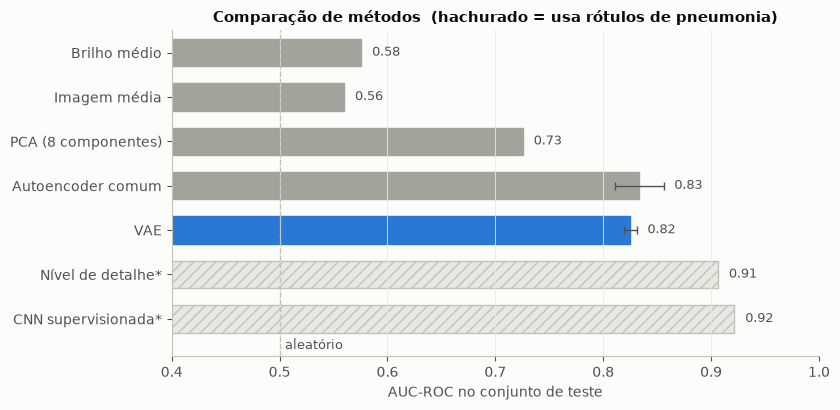

In [27]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
nomes = list(tabela.index)[::-1]
for k, nome in enumerate(nomes):
    linha = tabela.loc[nome]
    if nome == "VAE":
        cor, hatch = COR_NORMAL, None
    elif nome.endswith("*"):
        cor, hatch = "#e8e7e3", "///"
    else:
        cor, hatch = COR_NEUTRA, None
    ax.barh(k, linha["_auc"], xerr=linha["_dp"] or None, color=cor, hatch=hatch, edgecolor="#c3c2b7" if hatch else cor,
            height=0.62, error_kw={"ecolor": COR_TEXTO_2, "capsize": 3, "lw": 1})
    ax.text(linha["_auc"] + 0.01 + linha["_dp"], k, f"{linha['_auc']:.2f}", va="center", fontsize=9, color=COR_TEXTO_2)
ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes)
ax.axvline(0.5, color="#c3c2b7", lw=1, linestyle="--")
ax.text(0.505, -0.75, "aleatório", fontsize=9, color=COR_TEXTO_2, va="bottom")
ax.set_xlim(0.4, 1.0); ax.set_ylim(-0.85, len(nomes) - 0.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC-ROC no conjunto de teste")
ax.set_title("Comparação de métodos  (hachurado = usa rótulos de pneumonia)")
plt.tight_layout(); plt.show()

**Leitura da comparação:**

- **VAE e autoencoder comum ficam empatados** em AUC: a diferença entre eles é menor que a variação entre sementes. Os dois ficam bem acima do PCA, da imagem média e do brilho. Ou seja: o que faz a detecção funcionar é o **gargalo não linear** (comprimir o exame em 8 números com uma rede convolucional), e não a parte variacional em si. Para esta tarefa, ser "variacional" não melhorou a detecção.
- O que a parte variacional **acrescentou**: resultados **mais estáveis** entre sementes (desvio-padrão bem menor) e um **espaço latente organizado**, que permite gerar exames sintéticos, interpolar e inspecionar o que o modelo aprendeu (Seção 6) — o autoencoder comum não faz nada disso.
- A **CNN supervisionada** é melhor, como esperado: ela viu milhares de exemplos de pneumonia. A distância entre ela e o VAE é o "preço" de não ter rótulos da doença.
- A heurística de **nível de detalhe** chega perto da CNN *neste* dataset — mas ela é específica deste problema e foi descoberta usando os rótulos (Seção 9.2).
- Todos os métodos, inclusive a CNN, caem da validação para o teste: o conjunto de teste é mais difícil / diferente (Seção 9.3).

### 8.3 Limiar de decisão

O score é contínuo; para dizer "revisar com prioridade" é preciso um **limiar**. Comparamos duas formas de escolhê-lo, ambas usando só a **validação**:

- **Sem rótulos de pneumonia (percentil dos normais):** o limiar é o valor abaixo do qual fica uma fração escolhida dos exames normais de validação. Com o percentil 95, espera-se ~5% de falsos alarmes; com o 80, ~20%. É a opção realista para um detector de anomalias, que só conhece exemplos normais: você escolhe **quantos falsos alarmes aceita**.
- **Com rótulos (índice de Youden):** o limiar que maximiza *sensibilidade + especificidade − 1* na validação.

sensibilidade  \
limiar                                 conjunto                   
percentil 95 dos normais (sem rótulos) validação          0.465   
                                       teste              0.431   
percentil 90 dos normais (sem rótulos) validação          0.720   
                                       teste              0.726   
percentil 80 dos normais (sem rótulos) validação          0.889   
                                       teste              0.890   
Youden (com rótulos)                   validação          0.871   
                                       teste              0.859   

                                                  especificidade  \
limiar                                 conjunto                    
percentil 95 dos normais (sem rótulos) validação           0.948   
                                       teste               0.919   
percentil 90 dos normais (sem rótulos) validação           0.896   
                                       teste               0.803   
percentil 80 dos normais (sem rótulos) validação           0.800   
                                       teste               0.568   
Youden (com rótulos)                   validação           0.830   
                                       teste               0.637   

                                                  precisão (VPP)  
limiar                                 conjunto                   
percentil 95 dos normais (sem rótulos) validação           0.963  
                                       teste               0.898  
percentil 90 dos normais (sem rótulos) validação           0.952  
                                       teste               0.860  
percentil 80 dos normais (sem rótulos) validação           0.928  
                                       teste               0.775  
Youden (com rótulos)                   validação           0.936  
                                       teste               0.798

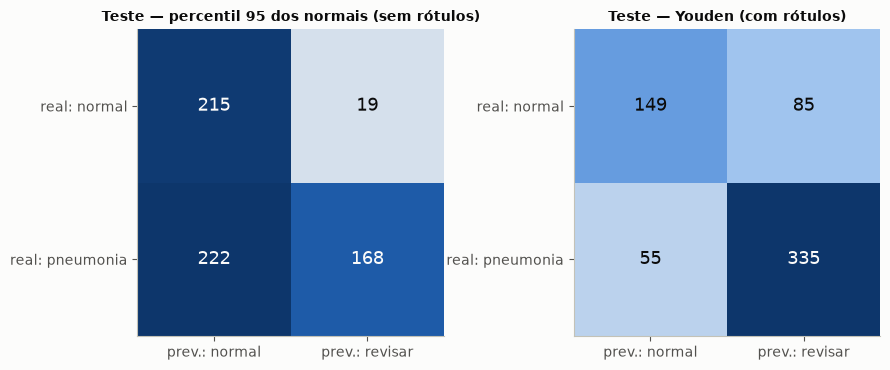

In [28]:
score_val = score_de_anomalia(x_val, rec_vae["val"], SIGMA)
limiares = {f"percentil {p} dos normais (sem rótulos)": float(np.percentile(score_val[y_val == 0], p))
            for p in [95, 90, 80]}
fpr_v, tpr_v, thr_v = roc_curve(y_val, score_val)
limiares["Youden (com rótulos)"] = float(thr_v[np.argmax(tpr_v - fpr_v)])

def metricas_no_limiar(y, score, limiar):
    pred = (score >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"sensibilidade": tp / (tp + fn), "especificidade": tn / (tn + fp),
            "precisão (VPP)": tp / max(tp + fp, 1), "matriz": np.array([[tn, fp], [fn, tp]])}

linhas, matrizes = [], {}
for nome, lim in limiares.items():
    for conjunto, y, sc in [("validação", y_val, score_val), ("teste", y_teste, score_teste)]:
        m = metricas_no_limiar(y, sc, lim)
        linhas.append({"limiar": nome, "conjunto": conjunto, **{k: round(v, 3) for k, v in m.items() if k != "matriz"}})
        if conjunto == "teste":
            matrizes[nome] = m["matriz"]
display(pd.DataFrame(linhas).set_index(["limiar", "conjunto"]))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, nome in zip(axes, ["percentil 95 dos normais (sem rótulos)", "Youden (com rótulos)"]):
    mat = matrizes[nome]
    ax.imshow(mat, cmap=CMAP_SEQ, vmin=0, vmax=mat.max())
    for (r, c), v in np.ndenumerate(mat):
        ax.text(c, r, str(v), ha="center", va="center", fontsize=13,
                color="#fcfcfb" if v > mat.max() * 0.55 else "#0b0b0b")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["prev.: normal", "prev.: revisar"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["real: normal", "real: pneumonia"])
    ax.grid(False); ax.set_title(f"Teste — {nome}", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura:**

- Com os limiares **sem rótulos**, a sensibilidade no teste fica bem próxima da observada na validação. Mas há um dilema: com **poucos falsos alarmes** (percentil 95), menos da metade das pneumonias é sinalizada; para pegar a grande maioria (percentil 80), é preciso aceitar muitos falsos alarmes.
- A **especificidade prevista não se mantém no teste**, e a diferença cresce à medida que o percentil desce: no 95 ela fica perto da prevista, no 80 cai bem abaixo. É a mudança de distribuição da Seção 9.3 — os normais do teste se concentram justamente na faixa de score em que esses limiares estão.
- O limiar de **Youden** (que usa rótulos) chega a um ponto de operação parecido com o do percentil 80 (sem rótulos), e sofre da mesma queda de especificidade no teste.
- **Conclusão prática:** como *alarme binário*, o score do VAE é limitado. Ele funciona melhor como ferramenta de **ordenação** da fila (próxima seção), em que não é preciso escolher um limiar. Num sistema real, qualquer limiar teria de ser **recalibrado com exames normais de cada hospital/equipamento**.

### 8.4 Simulação da fila de triagem

A pergunta prática (P4): **se a fila fosse ordenada pelo score do VAE, as pneumonias seriam vistas antes?**

**Curva de ganho:** ordenando todos os exames de teste pelo score, que fração das pneumonias é encontrada revisando os primeiros X% da fila?

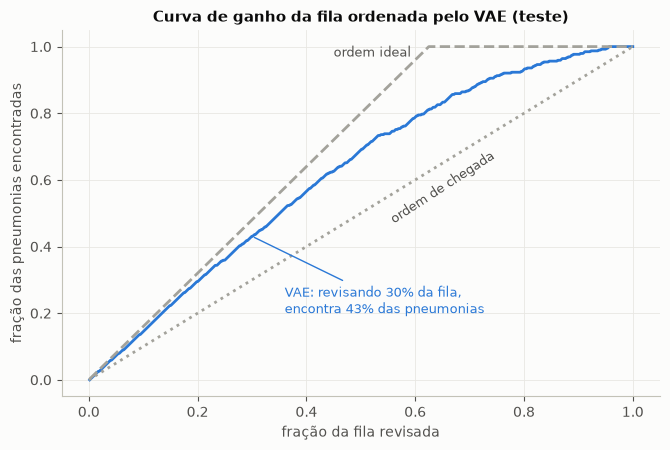

In [29]:
ordem = np.argsort(-score_teste)
frac_revisada = np.arange(1, len(ordem) + 1) / len(ordem)
frac_encontrada = np.cumsum(y_teste[ordem]) / y_teste.sum()
ideal = np.minimum(np.arange(1, len(ordem) + 1) / y_teste.sum(), 1)

fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.plot(frac_revisada, frac_encontrada, color=COR_NORMAL)
ax.plot(frac_revisada, ideal, color=COR_NEUTRA, linestyle="--")
ax.plot([0, 1], [0, 1], color=COR_NEUTRA, linestyle=":")
ax.text(0.45, 0.97, "ordem ideal", color=COR_TEXTO_2, fontsize=9)
ax.text(0.55, 0.47, "ordem de chegada", color=COR_TEXTO_2, fontsize=9, rotation=33)
k = int(0.3 * len(ordem))
ax.annotate(f"VAE: revisando 30% da fila,\nencontra {frac_encontrada[k - 1]:.0%} das pneumonias",
            xy=(0.3, frac_encontrada[k - 1]), xytext=(0.36, 0.2), fontsize=9, color=COR_NORMAL,
            arrowprops={"arrowstyle": "-", "color": COR_NORMAL, "lw": 1})
ax.set_xlabel("fração da fila revisada"); ax.set_ylabel("fração das pneumonias encontradas")
ax.set_title("Curva de ganho da fila ordenada pelo VAE (teste)")
plt.tight_layout(); plt.show()

O conjunto de teste tem 62,5% de pneumonias — muito acima da realidade de uma fila de pronto-atendimento. Para um cenário mais realista, **simulamos 2.000 filas de 100 exames com 10% de pneumonias** (sorteadas do teste) e comparamos a ordem de chegada com a ordem pelo score.

In [30]:
rng = np.random.default_rng(0)
i_norm, i_pneu = np.where(y_teste == 0)[0], np.where(y_teste == 1)[0]
pos_vae, pos_chegada, top10_vae, top10_chegada = [], [], [], []
for _ in range(2000):
    fila = np.concatenate([rng.choice(i_norm, 90, replace=False), rng.choice(i_pneu, 10, replace=False)])
    rng.shuffle(fila)                                  # ordem de chegada aleatória
    fila_vae = fila[np.argsort(-score_teste[fila])]    # ordem por score do VAE
    pos_chegada.append((np.where(y_teste[fila] == 1)[0] + 1).mean())
    pos_vae.append((np.where(y_teste[fila_vae] == 1)[0] + 1).mean())
    top10_chegada.append(y_teste[fila[:10]].sum())
    top10_vae.append(y_teste[fila_vae[:10]].sum())

display(pd.DataFrame({
    "posição média de uma pneumonia na fila (1 a 100)": [np.mean(pos_chegada), np.mean(pos_vae)],
    "pneumonias entre os 10 primeiros exames (de 10)": [np.mean(top10_chegada), np.mean(top10_vae)],
}, index=["ordem de chegada", "ordenada pelo VAE"]).round(1))

,posição média de uma pneumonia na fila (1 a 100),pneumonias entre os 10 primeiros exames (de 10)
ordem de chegada,50.6,1.0
ordenada pelo VAE,21.3,3.9


**Leitura:** em uma fila realista, ordenar pelo score do VAE **antecipa bastante** os exames com pneumonia em relação à ordem de chegada — sem que o modelo tenha visto um único caso de pneumonia no treino. É esse o valor de produto da PoC: priorização, não diagnóstico.

### 8.5 Experimentos com hiperparâmetros

Quanto as escolhas de arquitetura importam? Variamos o **tamanho do espaço latente** e o **peso β do KL**, um de cada vez, e medimos a AUC na **validação** (o teste não é usado para escolher nada). Cada configuração é treinada uma vez (semente 0), então diferenças pequenas (< 0,02) estão dentro da variação entre sementes.

Ablação concluída em 194s


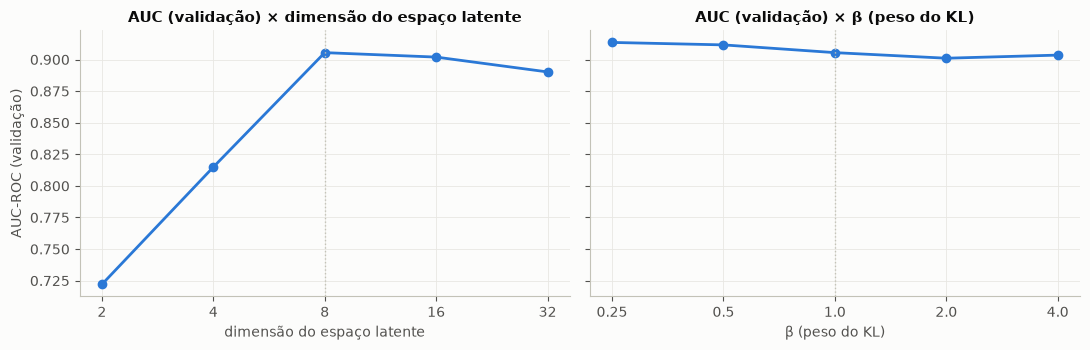

In [31]:
if CONFIG["rodar_ablacao"]:
    def auc_val_de(modelo):
        return auc(y_val, score_de_anomalia(x_val, reconstruir(modelo, x_val), SIGMA))

    resultados_latente, resultados_beta = {}, {}
    inicio = time.time()
    for d in [2, 4, 8, 16, 32]:
        m = vae if d == CONFIG["dim_latente"] else treinar_autoencoder(semente=0, dim_latente=d, verbose=False)[0]
        resultados_latente[d] = auc_val_de(m)
    for b in [0.25, 0.5, 1.0, 2.0, 4.0]:
        m = vae if b == CONFIG["beta"] else treinar_autoencoder(semente=0, beta=b, verbose=False)[0]
        resultados_beta[b] = auc_val_de(m)
    print(f"Ablação concluída em {time.time() - inicio:.0f}s")

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for ax, res, rotulo, atual in [(axes[0], resultados_latente, "dimensão do espaço latente", CONFIG["dim_latente"]),
                                   (axes[1], resultados_beta, "β (peso do KL)", CONFIG["beta"])]:
        xs = list(res.keys())
        ax.plot(range(len(xs)), list(res.values()), marker="o", markersize=6, color=COR_NORMAL)
        ax.set_xticks(range(len(xs))); ax.set_xticklabels([str(v) for v in xs])
        ax.axvline(xs.index(atual), color="#c3c2b7", lw=1, linestyle=":")
        ax.set_xlabel(rotulo); ax.set_title(f"AUC (validação) × {rotulo}")
    axes[0].set_ylabel("AUC-ROC (validação)")
    plt.tight_layout(); plt.show()
else:
    print("Ablação desativada em CONFIG['rodar_ablacao'].")

**Leitura:**

- **Tamanho do latente importa muito:** com 2 ou 4 dimensões, o modelo não consegue representar nem os normais direito (tudo vira "anomalia") e a AUC cai bastante. De 8 em diante a AUC estabiliza, com leve queda em 32 — um latente grande demais deixa o modelo flexível o bastante para reconstruir também as anomalias. O gargalo é o que torna o detector útil.
- **β quase não importa** nesta faixa (0,25 a 4): as diferenças ficam dentro da variação entre sementes. Coerente com a Seção 8.2: o que importa aqui é o gargalo, mais do que a regularização variacional.
- A configuração usada (latente 8, β = 1) fica na faixa boa em ambos.

## 9. Análise de erros e atalhos

### 9.1 Galeria de erros

Usando o limiar **sem rótulos** (percentil 95 dos normais de validação): os **falsos positivos** com maior score (normais que o modelo mandaria revisar) e os **falsos negativos** com menor score (pneumonias que passariam despercebidas).

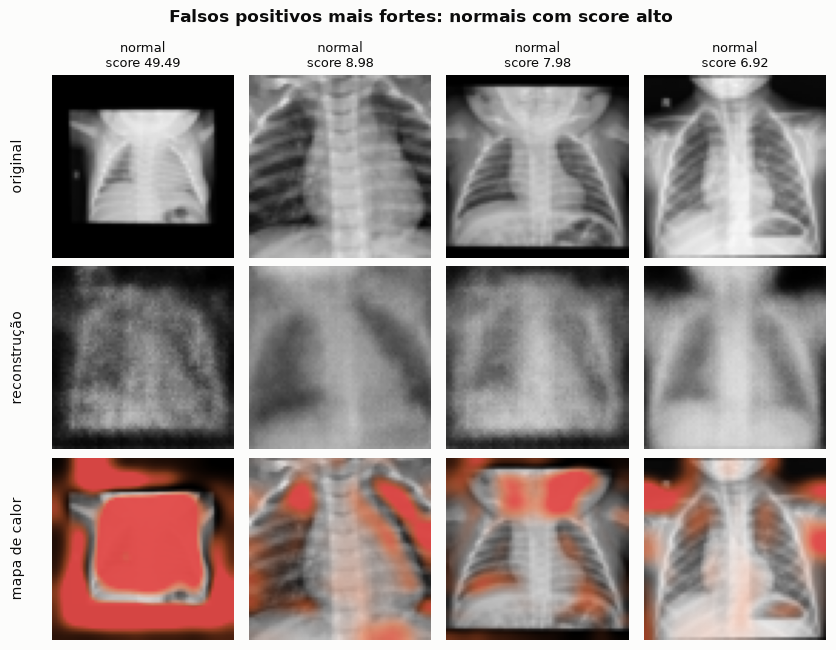

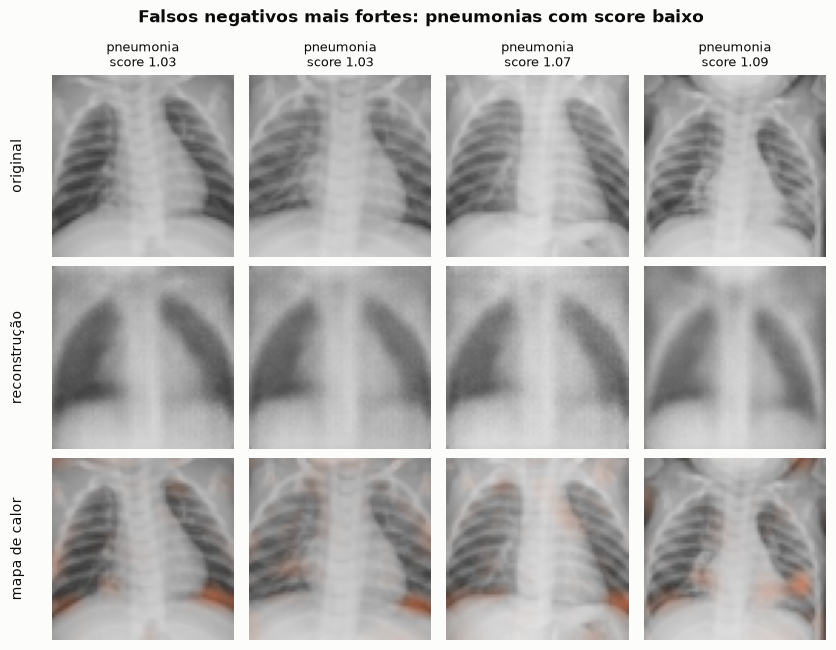

In [32]:
LIMIAR = limiares["percentil 95 dos normais (sem rótulos)"]
fp = [i for i in np.argsort(-score_teste) if y_teste[i] == 0 and score_teste[i] >= LIMIAR][:4]
fn = [i for i in np.argsort(score_teste) if y_teste[i] == 1 and score_teste[i] < LIMIAR][:4]
painel_exames(fp, "Falsos positivos mais fortes: normais com score alto")
painel_exames(fn, "Falsos negativos mais fortes: pneumonias com score baixo")

**Padrões observados:**

- **Falsos positivos** são exames com **enquadramento ou posicionamento atípico**: imagem menor dentro de uma moldura preta, tórax deslocado ou cortado, pescoço e ombros aparecendo, exposição diferente. O VAE não sabe reconstruir variações normais que não estavam no treino — e as trata como anomalia. O caso mais extremo (a moldura preta) é um problema de **aquisição**, não do paciente.
- **Falsos negativos** são pneumonias **discretas**: a olho nu, esses exames se parecem bastante com normais, e a opacidade, quando existe, é pequena ou difusa — a suavização (σ) a dilui.
- Nos dois casos, o mapa de calor acende muito **fora dos pulmões** (bordas, cantos, diafragma). Restringir o score à região pulmonar (segmentação) é um próximo passo natural.

### 9.2 O modelo está usando atalhos?

Um risco comum em IA médica é o modelo aprender um **atalho** — algo correlacionado com a doença no dataset, mas que não é a doença (brilho, contraste, marca do equipamento). Medimos a correlação do score do VAE com duas propriedades simples da imagem, **dentro de cada classe** (para não confundir com a própria diferença entre classes).

In [33]:
brilho_teste = x_teste.mean(dim=(1, 2, 3)).numpy()
linhas = []
for classe, nome in [(0, "normais"), (1, "pneumonias")]:
    m = y_teste == classe
    linhas.append({
        "classe": nome,
        "correlação score × brilho": spearmanr(score_teste[m], brilho_teste[m])[0],
        "correlação score × detalhe fino": spearmanr(score_teste[m], detalhe_teste[m])[0],
    })
display(pd.DataFrame(linhas).set_index("classe").round(2))
print(f"Lembrete — AUC no teste: brilho sozinho {auc(y_teste, brilho_teste):.3f} | "
      f"detalhe sozinho {auc(y_teste, -detalhe_teste):.3f} | VAE {auc_teste:.3f}")

,correlação score × brilho,correlação score × detalhe fino
classe,,
normais,0.01,0.13
pneumonias,-0.32,-0.08


Lembrete — AUC no teste: brilho sozinho 0.576 | detalhe sozinho 0.906 | VAE 0.822


**Leitura:**

- Nos **normais**, o score praticamente não depende do brilho nem do nível de detalhe da imagem.
- Nas **pneumonias**, a correlação com o brilho é *negativa*: pneumonias em imagens mais claras como um todo recebem score **menor**. Uma explicação provável: um aumento *global* de brilho é uma das variações normais que o VAE aprendeu a reproduzir (Seção 6.3), mas uma opacidade *localizada*, não. Além disso, o brilho sozinho separa as classes muito pior que o VAE. Ou seja, o VAE não é "um medidor de imagem mais branca".
- A heurística de **nível de detalhe** separa as classes melhor que o VAE neste dataset. Duas leituras possíveis, que esta PoC não consegue distinguir:
  1. **Fisiologia:** opacidades realmente apagam vasos e bordas, então "menos detalhe" é um sinal legítimo de pneumonia.
  2. **Viés do dataset:** exames com pneumonia podem ter sido adquiridos em outras condições (equipamento, resolução original, protocolo), e "menos detalhe" seria um artefato da coleta.
- Em ambos os casos, a heurística só funciona para este tipo de anomalia e só foi descoberta **olhando os rótulos**. O VAE, por construção, não depende de saber como a anomalia se parece — e, com a suavização, ele ignora justamente o detalhe fino.

### 9.3 Validação × teste: mudança de distribuição

Todos os métodos perdem desempenho da validação para o teste. No dataset original (Kermany et al., 2018), o conjunto de teste é um lote separado de exames; a validação do MedMNIST foi sorteada de dentro do treino. Comparamos os scores dos **exames normais** nos dois conjuntos:

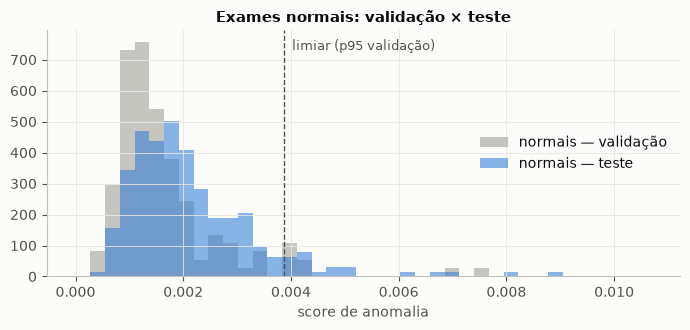

Normais do teste acima do limiar: 8% (esperado pela validação: ~5%)


In [34]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(0, np.percentile(np.concatenate([score_val, score_teste]), 99), 40)
ax.hist(score_val[y_val == 0], bins=bins, color=COR_NEUTRA, alpha=0.6, density=True, label="normais — validação")
ax.hist(score_teste[y_teste == 0], bins=bins, color=COR_NORMAL, alpha=0.55, density=True, label="normais — teste")
ax.axvline(LIMIAR, color=COR_TEXTO_2, lw=1, linestyle="--")
ax.text(LIMIAR, ax.get_ylim()[1] * 0.92, "  limiar (p95 validação)", color=COR_TEXTO_2, fontsize=9)
ax.set_xlabel("score de anomalia"); ax.set_title("Exames normais: validação × teste"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()
frac = (score_teste[y_teste == 0] >= LIMIAR).mean()
print(f"Normais do teste acima do limiar: {frac:.0%} (esperado pela validação: ~5%)")

**Leitura:** os normais do teste têm scores um pouco mais altos que os da validação — para o VAE, eles são "levemente anômalos", mesmo sendo saudáveis —, e mais deles passam do limiar do que o previsto. A mudança é moderada, mas aparece em todos os métodos (até a CNN supervisionada perde desempenho no teste), indicando que o lote de teste é diferente do de treino. Isso ilustra o maior risco prático de detectores de anomalia: **qualquer mudança no "normal" (equipamento, protocolo, população) vira alarme**.

## 10. Conclusões e limitações

Os números citados abaixo são os desta execução; ao rodar novamente (outra GPU, outra versão de biblioteca) eles podem variar um pouco, principalmente na segunda casa decimal.

In [35]:
vae_auc = tabela.loc["VAE", "_auc"]
print(f"P1  AUC do VAE no teste (sem ver pneumonia): {vae_auc:.3f} (média de {len(modelos_vae)} sementes); "
      f"erro pixel a pixel ingênuo: {auc(y_teste, score_ingenuo_teste):.3f}")
print(f"P2  Melhor alternativa sem rótulos: "
      f"{tabela[tabela['usa rótulos de pneumonia?'] == 'não'].drop(index='VAE')['_auc'].idxmax()} "
      f"({tabela[tabela['usa rótulos de pneumonia?'] == 'não'].drop(index='VAE')['_auc'].max():.3f}); "
      f"CNN supervisionada: {tabela.loc['CNN supervisionada*', '_auc']:.3f}")
print(f"P4  Fila realista (10% de pneumonias): posição média de uma pneumonia "
      f"{np.mean(pos_chegada):.0f} → {np.mean(pos_vae):.0f}; pneumonias entre os 10 primeiros: "
      f"{np.mean(top10_chegada):.1f} → {np.mean(top10_vae):.1f}")
print(f"P5  Normais do teste acima do limiar sem rótulos: {frac:.0%} (esperado ~5%)")

P1  AUC do VAE no teste (sem ver pneumonia): 0.825 (média de 3 sementes); erro pixel a pixel ingênuo: 0.617
P2  Melhor alternativa sem rótulos: Autoencoder comum (0.833); CNN supervisionada: 0.922
P4  Fila realista (10% de pneumonias): posição média de uma pneumonia 51 → 21; pneumonias entre os 10 primeiros: 1.0 → 3.9
P5  Normais do teste acima do limiar sem rótulos: 8% (esperado ~5%)


### Respostas às perguntas da PoC

**P1 — O VAE separa pneumonia de normal sem nunca ter visto pneumonia?** Sim, de forma moderada — **mas não do jeito ingênuo**. O erro de reconstrução pixel a pixel é fraco, porque mistura dois sinais opostos: o erro de detalhe fino (maior nos normais, que têm mais detalhe a perder) e o erro de regiões (maior nas pneumonias). Comparando exame e reconstrução **em baixa frequência**, o score passa a funcionar bem melhor.

**P2 — É melhor que alternativas simples? Quão longe do supervisionado?** Supera com folga as alternativas lineares e heurísticas sem rótulos (brilho, imagem média, PCA), mas **empata com o autoencoder comum**: o que faz a detecção funcionar é o gargalo não linear, não a parte variacional. O VAE é mais estável entre sementes e oferece um espaço latente gerativo (Seção 6), mas não detecta melhor. Fica abaixo da CNN supervisionada — essa diferença é o custo de não usar rótulos da doença.

**P3 — O mapa de calor aponta regiões plausíveis?** Em boa parte das pneumonias, sim (campos pulmonares). Mas ele também acende em bordas, ombros e áreas de posicionamento atípico, e é grosseiro (64×64 px, suavizado). Serve como pista visual, não como localização precisa.

**P4 — Quanto a fila melhoraria?** Em uma fila simulada com 10% de pneumonias, ordenar pelo score do VAE coloca as pneumonias bem mais cedo do que a ordem de chegada. Como ferramenta de **priorização**, a ideia é promissora.

**P5 — Onde e por que erra?** Falsos positivos: variações normais não vistas no treino (enquadramento, posicionamento, exposição) e mudança de distribuição entre conjuntos. Falsos negativos: pneumonias discretas, com opacidades pequenas ou difusas. Como alarme binário, a sensibilidade é baixa quando se exige poucos falsos alarmes.

### Limitações

- **Dados:** só crianças de 1 a 5 anos, de um único hospital; apenas ~1.200 exames normais para treinar; resolução de 64×64 px (raios-X clínicos têm milhares de pixels por lado).
- **Atalhos e viés:** neste dataset, uma propriedade de baixo nível (nível de detalhe fino) separa as classes melhor que o VAE. Não é possível afirmar quanto disso é fisiologia e quanto é viés de aquisição.
- **Mudança de distribuição:** o limiar calibrado na validação não se transfere bem para o teste. Em produção, seria preciso recalibrar por hospital/equipamento e monitorar continuamente.
- **Score dependente de escolhas:** a suavização (σ) foi escolhida com uma pequena validação rotulada; sem nenhum rótulo, essa escolha seria mais difícil.
- **Reconstruções borradas:** inerentes ao VAE; limitam a precisão do mapa de calor e obrigam a ignorar o detalhe fino no score.
- **A parte variacional não melhorou a detecção:** o autoencoder comum, com a mesma arquitetura, chega à mesma AUC.
- **"Qualquer anomalia" não foi testada:** só avaliamos pneumonia. A promessa de detectar doenças nunca vistas continua uma hipótese.
- **Ética:** não é um dispositivo médico; os resultados não têm validação clínica; a decisão é sempre do profissional.

### Próximos passos

- Restringir o score aos **campos pulmonares** (segmentação) para reduzir falsos positivos de bordas e posicionamento.
- Maior resolução (128 ou 224 px) com arquiteturas mais profundas.
- Testar em outros datasets de tórax (adultos, outros hospitais, outras doenças) para medir generalização.
- Variações do método: VAE com perda perceptual, *VQ-VAE*, ou modelos de difusão para reconstrução.
- Uma interface (por exemplo, Gradio) para demonstrar a triagem: envio de exame → score, mapa de calor e posição na fila.

### Referências

- Kingma, D. P.; Welling, M. *Auto-Encoding Variational Bayes*. ICLR, 2014.
- Higgins, I. et al. *β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework*. ICLR, 2017.
- Bowman, S. R. et al. *Generating Sentences from a Continuous Space*. CoNLL, 2016.
- An, J.; Cho, S. *Variational Autoencoder based Anomaly Detection using Reconstruction Probability*. SNU Data Mining Center, 2015.
- Baur, C. et al. *Autoencoders for Unsupervised Anomaly Segmentation in Brain MR Images: A Comparative Study*. Medical Image Analysis, 2021.
- Nalisnick, E. et al. *Do Deep Generative Models Know What They Don't Know?* ICLR, 2019.
- Serrà, J. et al. *Input Complexity and Out-of-distribution Detection with Likelihood-based Generative Models*. ICLR, 2020.
- Kermany, D. S. et al. *Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning*. Cell, 2018.
- Yang, J. et al. *MedMNIST v2: A Large-Scale Lightweight Benchmark for 2D and 3D Biomedical Image Classification*. Scientific Data, 2023.

## 11. Salvando o modelo

Salvamos os pesos do VAE principal junto com tudo o que é preciso para reproduzir o score (configuração, σ e limiar). No Colab, o arquivo fica na pasta da sessão — baixe-o pelo painel de arquivos ou salve no Google Drive se quiser reutilizar (por exemplo, numa interface de demonstração).

In [36]:
os.makedirs("pesos", exist_ok=True)
caminho = "pesos/vae_pneumonia.pt"
torch.save({
    "state_dict": {k: v.cpu() for k, v in vae.state_dict().items()},
    "config": CONFIG,
    "sigma": SIGMA,
    "limiar_p95": LIMIAR,
    "vmax_mapa": VMAX_MAPA,
}, caminho)
print(f"Modelo salvo em {caminho} ({os.path.getsize(caminho) / 1e6:.1f} MB)")

Modelo salvo em pesos/vae_pneumonia.pt (6.0 MB)
